# 기상 변수 기반 시간당 전력 피크 수요 예측 및 냉난방 부하

**작성자:** 안재원 &nbsp;&nbsp;|&nbsp;&nbsp; **작성일:** 2026-08-13 

## #1. 분석 개요

**분석 주제**

> 공개 데이터인 Power Load with Weather and Economic Dataset으로 ** 기상 변수 기반 시간당 전력 피크 수요 예측 및 냉난방 부하 **를 확인한다.
> 시계열분석 전 과정(품질 점검 → EDA → 모델링 → 진단 → 해석)을 연습하기 위한 분석이다.

**분석 질문**

**종속변수:** `load_demand_MW` (연속형, 시간당 전력수요량 / 단위 MW/h) → 예측 문제

**이번 노트북에서 연습할 기법**

> 파생변수**(체감온도 및 불쾌지수)**를 추가하여 미래 전력량 예측
> 시계열 분석에서 결측치에 대한 선형 보간을 어떻게 실행할건지.
> 

#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**

In [1]:
from helper import *
from IPython.display import display, Markdown

## 노트북에서 직접 호출하지는 않지만, 분석 환경(버전) 확인용으로 함께 참조한다.
import pandas as pd
import numpy as np
import statsmodels.api as sm

---
## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [2]:
origin = pd.read_csv(r"C:\Users\LG\Desktop\주영아강사님\Jaewon\# 포트폴리오\# 1. 데이터셋\power_system_load_dataset.csv", encoding='utf-8')
origin.tail()

,datetime,load_demand_MW,temperature_C,humidity_%,solar_irradiation_Wm2,population,gni_per_capita_usd,power_price_usd_per_kwh,day_of_week,hour_of_day,is_holiday,season,year,month,week_of_year,lag_1_hour_load,lag_1_day_load,moving_avg_7_day
17491,2023-12-31 19:00:00,277.396662,9.640535,77.140488,0.0,100288.243288,11755.602742,0.100199,6,19,1,Winter,2023,12,52,263.098725,272.806486,281.500855
17492,2023-12-31 20:00:00,271.725090,10.143328,77.699995,0.0,99933.816791,11898.445168,0.102152,6,20,1,Winter,2023,12,52,277.396662,293.423788,281.094598
17493,2023-12-31 21:00:00,304.078170,11.393263,71.341657,0.0,99382.420677,12042.704167,0.105439,6,21,1,Winter,2023,12,52,271.725090,311.493044,281.152347
17494,2023-12-31 22:00:00,340.431919,11.274666,72.788579,0.0,99560.036620,11943.916022,0.102642,6,22,1,Winter,2023,12,52,304.078170,314.885286,281.062356
17495,2023-12-31 23:00:00,358.725993,10.339081,73.896611,0.0,99782.688863,12018.183951,0.100144,6,23,1,Winter,2023,12,52,340.431919,332.942881,281.396836


#### 2-2. 출처와 분석 단위

- **출처:** — Kaggle 재배포본 `Power Load with Weather and Economic Dataset`
- **수집 기간:** 2022년 ~ 2023년 
- **분석 단위:** 1행 = (MW/h)

#### 2-3. 변수 정의서

| 변수명 | 의미 | 역할 | 척도 | 단위 |
|---|---|---|---|---|
| `datetime` | 날짜 | 날짜인덱스 | Date | yyyy-mm-dd-hh:mm:ss |
| `load_demand_MW` | 전력수요량 | 종속변수 | 연속형 | MW |
| `temperature_C` | 기온 | 독립변수 | 연속형 | ℃ |
| `humidity_%` | 습도 | 독립변수 | 연속형 | % |
| `solar_irradiation_Wm2` | 일조량 | 독립변수 | 연속형 | Wm2/h |
| `population` | 인구 | 독립변수 | 연속형 | 명 |
| `gni_per_capita_usd` | 1인당 국민총소득 | 독립변수 | 연속형 | $ |
| `power_price_usd_per_kwh` | kwh당 전력 단가 | 독립변수 | 연속형 | $ |
| `day_of_week` | 요일 정보(0:월요일 ~ 6:일요일) | 시간변수 | 연속형 | 숫자 | 
| `hour_of_day` | 시간대 (0~23시) | 시간변수 | 연속형 | 숫자 |
| `is_holiday` | 공휴일 여부(1:공휴일, 0:평일) | 시간변수 | 명목형 | 숫자 |
| `season` | 계절 | 시간변수 | 명목형 | Spring, Summer, Autumn, Winter |
| `year` | 년도 | 시간변수 | 연속형 | yyyy |
| `month` | 월 | 시간변수 | 연속형 | mm |
| `week_of_year` | 연중 주차(1~52주차) | 시간변수 | 연속형 | int |
| `lag_1_hour_load` | 직전1시간 전 전력 수요량 | 시계열 파생변수 | 연속형 | MW/h |
| `lag_1_day_load` | 어제 동일 시간 전력 수요량 | 시계열 파생변수 | 연속형 | MW/h |
| `moving_avg_7_day` | 지난 7일간의 이동 평균 전력 수요량 | 시계열 파생변수 | 연속형 | MW/7d |


#### 2-4. 초기 가설

- **H1.** 기온과 전력수요는 비선형적인 관계를 가진다
- **H2.** 평일과 공휴일의 전력 수요패턴은 다른 구조를 보인다
- **H3.** 기온과 습도가 결합된 '체감 온도/불쾌지수'가 여름철 피크 전력 예측력을 높일 것이다.

#### 2-5. 데이터의 한계

- **시점:** 2023년~2024년 기후 및 전력소비량 기반의 **시계열 데이터**다. 현재 시장에 그대로 적용할 수 없지만 시간에 따른 변화를 볼 수 있다.
- **관측 단위:** 
- **종속변수 절단:** `load_demand_MW`가 0에서 **하한 절단(censoring)** 되어 있다. 0에 정확히 겹친 관측치 가 많다. 전력수요량은 0이하가 나올 수가 없다.

---
## #3. 품질 점검 및 기본 전처리

> 이 장에서는 **삭제 처리는 안함** 결측치 대체**Nan 처리** ,이상치의 대체는 **Nan 처리 한다**에서 한다.
> 결측치의 Nan 대체는 시계열 축이 깨져버리므로 추후 보간을 이용하여 대체 처리한다.

#### 3-1. 데이터 구조 점검

##### 1) 자료형 확인

In [3]:
origin.info()

<class 'pandas.DataFrame'>
RangeIndex: 17496 entries, 0 to 17495
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   datetime                 17496 non-null  str    
 1   load_demand_MW           17496 non-null  float64
 2   temperature_C            17496 non-null  float64
 3   humidity_%               17496 non-null  float64
 4   solar_irradiation_Wm2    17496 non-null  float64
 5   population               17496 non-null  float64
 6   gni_per_capita_usd       17496 non-null  float64
 7   power_price_usd_per_kwh  17496 non-null  float64
 8   day_of_week              17496 non-null  int64  
 9   hour_of_day              17496 non-null  int64  
 10  is_holiday               17496 non-null  int64  
 11  season                   17496 non-null  str    
 12  year                     17496 non-null  int64  
 13  month                    17496 non-null  int64  
 14  week_of_year             17496 no

##### 1-2) 자료형 변환 (시계열)

`datatime`은 날짜이므로 시계열 분석을 위한 시계열 변환 및 인덱스를 설정해준다.

In [4]:
df = my_qtcheck.set_type(origin, as_datetime=["datetime"])
df = df.set_index('datetime').sort_index().asfreq("h")
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17496 entries, 0 to 17495
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   datetime                 17496 non-null  datetime64[us]
 1   load_demand_MW           17496 non-null  float64       
 2   temperature_C            17496 non-null  float64       
 3   humidity_%               17496 non-null  float64       
 4   solar_irradiation_Wm2    17496 non-null  float64       
 5   population               17496 non-null  float64       
 6   gni_per_capita_usd       17496 non-null  float64       
 7   power_price_usd_per_kwh  17496 non-null  float64       
 8   day_of_week              17496 non-null  int64         
 9   hour_of_day              17496 non-null  int64         
 10  is_holiday               17496 non-null  int64         
 11  season                   17496 non-null  str           
 12  year                     17496 non-null  in

##### 1-3) 중복 검사 및 중복 데이터 삭제

In [5]:
df1 = my_qtcheck.check_duplicates(df)
df1.head()
df1.info()

중복된 행의 수: 0
<class 'pandas.DataFrame'>
DatetimeIndex: 17496 entries, 2022-01-02 00:00:00 to 2023-12-31 23:00:00
Freq: h
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   load_demand_MW           17496 non-null  float64
 1   temperature_C            17496 non-null  float64
 2   humidity_%               17496 non-null  float64
 3   solar_irradiation_Wm2    17496 non-null  float64
 4   population               17496 non-null  float64
 5   gni_per_capita_usd       17496 non-null  float64
 6   power_price_usd_per_kwh  17496 non-null  float64
 7   day_of_week              17496 non-null  int64  
 8   hour_of_day              17496 non-null  int64  
 9   is_holiday               17496 non-null  int64  
 10  season                   17496 non-null  str    
 11  year                     17496 non-null  int64  
 12  month                    17496 non-null  int64  
 13  week_of_year             17496 n

### 1-4) 파생변수 생성 (HDD / CDD / 불쾌지수)

In [6]:
# HDD/CDD 파생변수 생성
base_temp = 18.0                    # 기준온도 18도

diff = df1["temperature_C"] - base_temp
df1["HDD"] = (-diff).clip(lower=0)   # 기준보다 추울 때만 양수
df1["CDD"] = diff.clip(lower=0)      # 기준보다 더울 때만 양수

# 불쾌지수 생성
"""불쾌지수 = T - 0.55 * (1 - 0.01 * RH) * (T - 14.5)
    T : 온도 ("temperature_C")
    RH : 습도 ("humidity_%")

    기준 :
        쾌적 : 68 이하
        보통 : 68 ~ 75 미만
        약간불쾌 : 75 ~ 80 미만
        불쾌 : 80 ~ 83 미만
        매우불쾌 : 83 이상
"""

T = df1["temperature_C"]
RH = df1["humidity_%"]

df1["discomfort_index"] = T - 0.55 * (1 - 0.01 * RH) * (T - 14.5)

bins = [-np.inf, 68, 75, 80, 83, np.inf]
labels = ["쾌적", "보통", "약간불쾌", "불쾌", "매우불쾌"]
df1["discomfort_level"] = pd.cut(df1["discomfort_index"], bins=bins, labels=labels)

df1[["temperature_C", "humidity_%", "HDD", "CDD", "discomfort_index", "discomfort_level"]].head()
df1.shape

(17496, 21)

##### 1-5) 결측치 확인

In [7]:
my_qtcheck.check_missing_values(df1)

,Missing Count,Missing Ratio (%)
load_demand_MW,0,0.0
temperature_C,0,0.0
humidity_%,0,0.0
solar_irradiation_Wm2,0,0.0
population,0,0.0
gni_per_capita_usd,0,0.0
power_price_usd_per_kwh,0,0.0
day_of_week,0,0.0
hour_of_day,0,0.0
is_holiday,0,0.0


##### 1-6) 이상치 확인 (IQR 기준)

`numerical_summary()` 는 기술통계량과 함께 **IQR × 1.5 경계**를 벗어난 이상치의 개수·비율을 계산한다.

In [8]:
num_desc = my_qtcheck.numerical_summary(df1)
num_desc.T

,load_demand_MW,temperature_C,humidity_%,solar_irradiation_Wm2,population,gni_per_capita_usd,power_price_usd_per_kwh,day_of_week,hour_of_day,is_holiday,year,month,week_of_year,lag_1_hour_load,lag_1_day_load,moving_avg_7_day,HDD,CDD,discomfort_index
count,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0
mean,289.910707,10.008582,49.922705,50.435957,100001.827607,12001.214051,0.0999,3.004115,11.5,0.286694,2022.500686,6.533608,26.534979,289.908035,289.904915,289.921534,9.519613,1.528195,11.918181
std,40.989025,10.805678,21.807836,114.469958,496.084751,735.342425,0.014988,2.001767,6.922384,0.45223,0.500014,3.44423,15.028129,40.986062,40.989051,5.947413,8.974446,2.66921,7.622255
min,175.598255,-12.169253,1.984893,0.0,97852.304508,10268.822355,0.060365,0.0,0.0,0.0,2022.0,1.0,1.0,175.598255,175.598255,278.870952,0.0,0.0,-4.335967
25%,257.094659,-0.403599,29.514736,0.0,99666.075464,11325.4262,0.08664,1.0,5.75,0.0,2022.0,4.0,14.0,257.094659,257.088364,284.345667,0.0,0.0,4.78365
50%,289.826316,10.03313,49.746454,0.0,100004.780342,11990.93879,0.099742,3.0,11.5,0.0,2023.0,7.0,27.0,289.826316,289.849656,289.759439,7.96687,0.0,11.385165
75%,322.538982,20.425231,70.397555,0.0,100336.710614,12675.92728,0.113185,5.0,17.25,1.0,2023.0,10.0,40.0,322.522868,322.538982,295.697071,18.403599,2.425231,19.12762
max,418.822736,31.146417,97.422296,499.99537,101768.265827,13678.636334,0.136121,6.0,23.0,1.0,2023.0,12.0,52.0,418.822736,418.822736,301.100502,30.169253,13.146417,28.16335
rel_diff,0.000291,0.002447,0.003543,inf,0.00003,0.000857,0.00159,0.001372,0.0,inf,0.000247,0.066627,0.017223,0.000282,0.000191,0.000559,0.1949,inf,0.046817
rdiff_flag,similar,similar,similar,large_diff,similar,similar,similar,similar,similar,large_diff,similar,similar,similar,similar,similar,similar,diff,large_diff,similar


**해석** — 결측치 ( 0 )건, 이상치 ( 0 )건 삭제. 관측치 ( 17496 ) → ( 17496 ).

삭제 기준과 그렇게 정한 이유

- **결측치는 0건**이라 삭제 대상이 없었다.
- **IQR 이상치는 삭제하지 않았다.**
  - `solar_irradiation_wm2` 4365건(24.9%), `population` 104건(0.6%) 총 4405건 가까이 검출된다.
  - 이들은 오류값이 아니라 **일조량이 없는 시간이 있는 것**처럼 실재하는 데이터의 특성이다.
  - 전량 삭제하면 시계열 축이 사라지고 시계열분석을 할 수가 없는 점으로 삭제하지 않았다.
  - → 삭제 대신 **#6의 `2_이상치대체` 체크포인트에서 Nan으로 대체**하고, 그 효과를 성능표로 검증 후 이동보간 및 지수보간으로 대체할 예정이다.

##### 1-6) 연속형 변수의 기술 통계량을 전치 형태로 출력

In [9]:
num_desc.T

,load_demand_MW,temperature_C,humidity_%,solar_irradiation_Wm2,population,gni_per_capita_usd,power_price_usd_per_kwh,day_of_week,hour_of_day,is_holiday,year,month,week_of_year,lag_1_hour_load,lag_1_day_load,moving_avg_7_day,HDD,CDD,discomfort_index
count,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0,17496.0
mean,289.910707,10.008582,49.922705,50.435957,100001.827607,12001.214051,0.0999,3.004115,11.5,0.286694,2022.500686,6.533608,26.534979,289.908035,289.904915,289.921534,9.519613,1.528195,11.918181
std,40.989025,10.805678,21.807836,114.469958,496.084751,735.342425,0.014988,2.001767,6.922384,0.45223,0.500014,3.44423,15.028129,40.986062,40.989051,5.947413,8.974446,2.66921,7.622255
min,175.598255,-12.169253,1.984893,0.0,97852.304508,10268.822355,0.060365,0.0,0.0,0.0,2022.0,1.0,1.0,175.598255,175.598255,278.870952,0.0,0.0,-4.335967
25%,257.094659,-0.403599,29.514736,0.0,99666.075464,11325.4262,0.08664,1.0,5.75,0.0,2022.0,4.0,14.0,257.094659,257.088364,284.345667,0.0,0.0,4.78365
50%,289.826316,10.03313,49.746454,0.0,100004.780342,11990.93879,0.099742,3.0,11.5,0.0,2023.0,7.0,27.0,289.826316,289.849656,289.759439,7.96687,0.0,11.385165
75%,322.538982,20.425231,70.397555,0.0,100336.710614,12675.92728,0.113185,5.0,17.25,1.0,2023.0,10.0,40.0,322.522868,322.538982,295.697071,18.403599,2.425231,19.12762
max,418.822736,31.146417,97.422296,499.99537,101768.265827,13678.636334,0.136121,6.0,23.0,1.0,2023.0,12.0,52.0,418.822736,418.822736,301.100502,30.169253,13.146417,28.16335
rel_diff,0.000291,0.002447,0.003543,inf,0.00003,0.000857,0.00159,0.001372,0.0,inf,0.000247,0.066627,0.017223,0.000282,0.000191,0.000559,0.1949,inf,0.046817
rdiff_flag,similar,similar,similar,large_diff,similar,similar,similar,similar,similar,large_diff,similar,similar,similar,similar,similar,similar,diff,large_diff,similar


**해석**

- **중심수준:** `MEDV`의 평균은 22.5천 달러, 중앙값은 21.2천 달러로 비슷하다(상대 차이 6.3%).
  독립변수는 단위가 제각각이다 — `TAX`는 평균 408, `NOX`는 0.55로 **약 700배 차이**가 난다. 계수를 직접 비교할 수 없으므로 #8에서 표준화계수(β)로 본다.
- **퍼짐 정도:** `CRIM`(표준편차 8.60, 최댓값 88.98)과 `ZN`(23.32)의 산포가 압도적으로 크다. 두 변수 모두 0 근처에 대부분이 몰려 있고 소수의 극단값이 꼬리를 만든다.
- **비대칭 신호:** 왜도 기준 변환 후보는 `CRIM`(+5.22), `ZN`(+2.23), `MEDV`(+1.11), `DIS`(+1.01), `RAD`(+1.01), `LSTAT`(+0.91)로 **우측 꼬리**이고,
  `B`(−2.89)만 **좌측 꼬리**다. `log_need` 열이 각각 `log` / `log1p` / `reverse_log1p`로 판정해 준다 → **#6의 `1_로그변환` 체크포인트 대상**.
- **첨도:** `CRIM`(37.13)과 `B`(7.23)가 극단적으로 뾰족하다. 로그 변환으로 완화될 것으로 기대한다.
- 명목형 `CHAS`는 506건 중 인접(1)이 35건뿐인 **불균형 변수**다. 집단 크기 차이가 크므로 검정 결과를 조심해서 읽어야 한다.

#### 3. 이 장의 결론

- 분석용 데이터 최종 크기: **17496행 × 21열** (삭제 없음)
- 삭제 내역과 근거:
  - 중복 0건 / 결측 0건 → 삭제 없음
  - 식별자 열 없음 → 삭제할 열 없음
  - IQR 이상치는 **삭제하지 않고 #6에서 경계값 대체 여부를 성능으로 비교** → 오류값이 아니라 실재하는 지역 특성이고, 삭제하면 표본이 절반 가까이 사라짐

---
## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 분포 확인

### 1) 시계열 인덱스 및 타겟변수 확인

In [10]:
target = df1["load_demand_MW"]

print(
    f"기간: {df1.index[0]:%Y-%m-%d %H:%M} ~ {df1.index[-1]:%Y-%m-%d %H:%M} "
    f"| {len(df1):,}시간 | 간격 {df1.index.freqstr}"
)

기간: 2022-01-02 00:00 ~ 2023-12-31 23:00 | 17,496시간 | 간격 h


### 2) 전력소비량 그래프 확인

### 2-1) 전체 전력수요 시계열 그래프

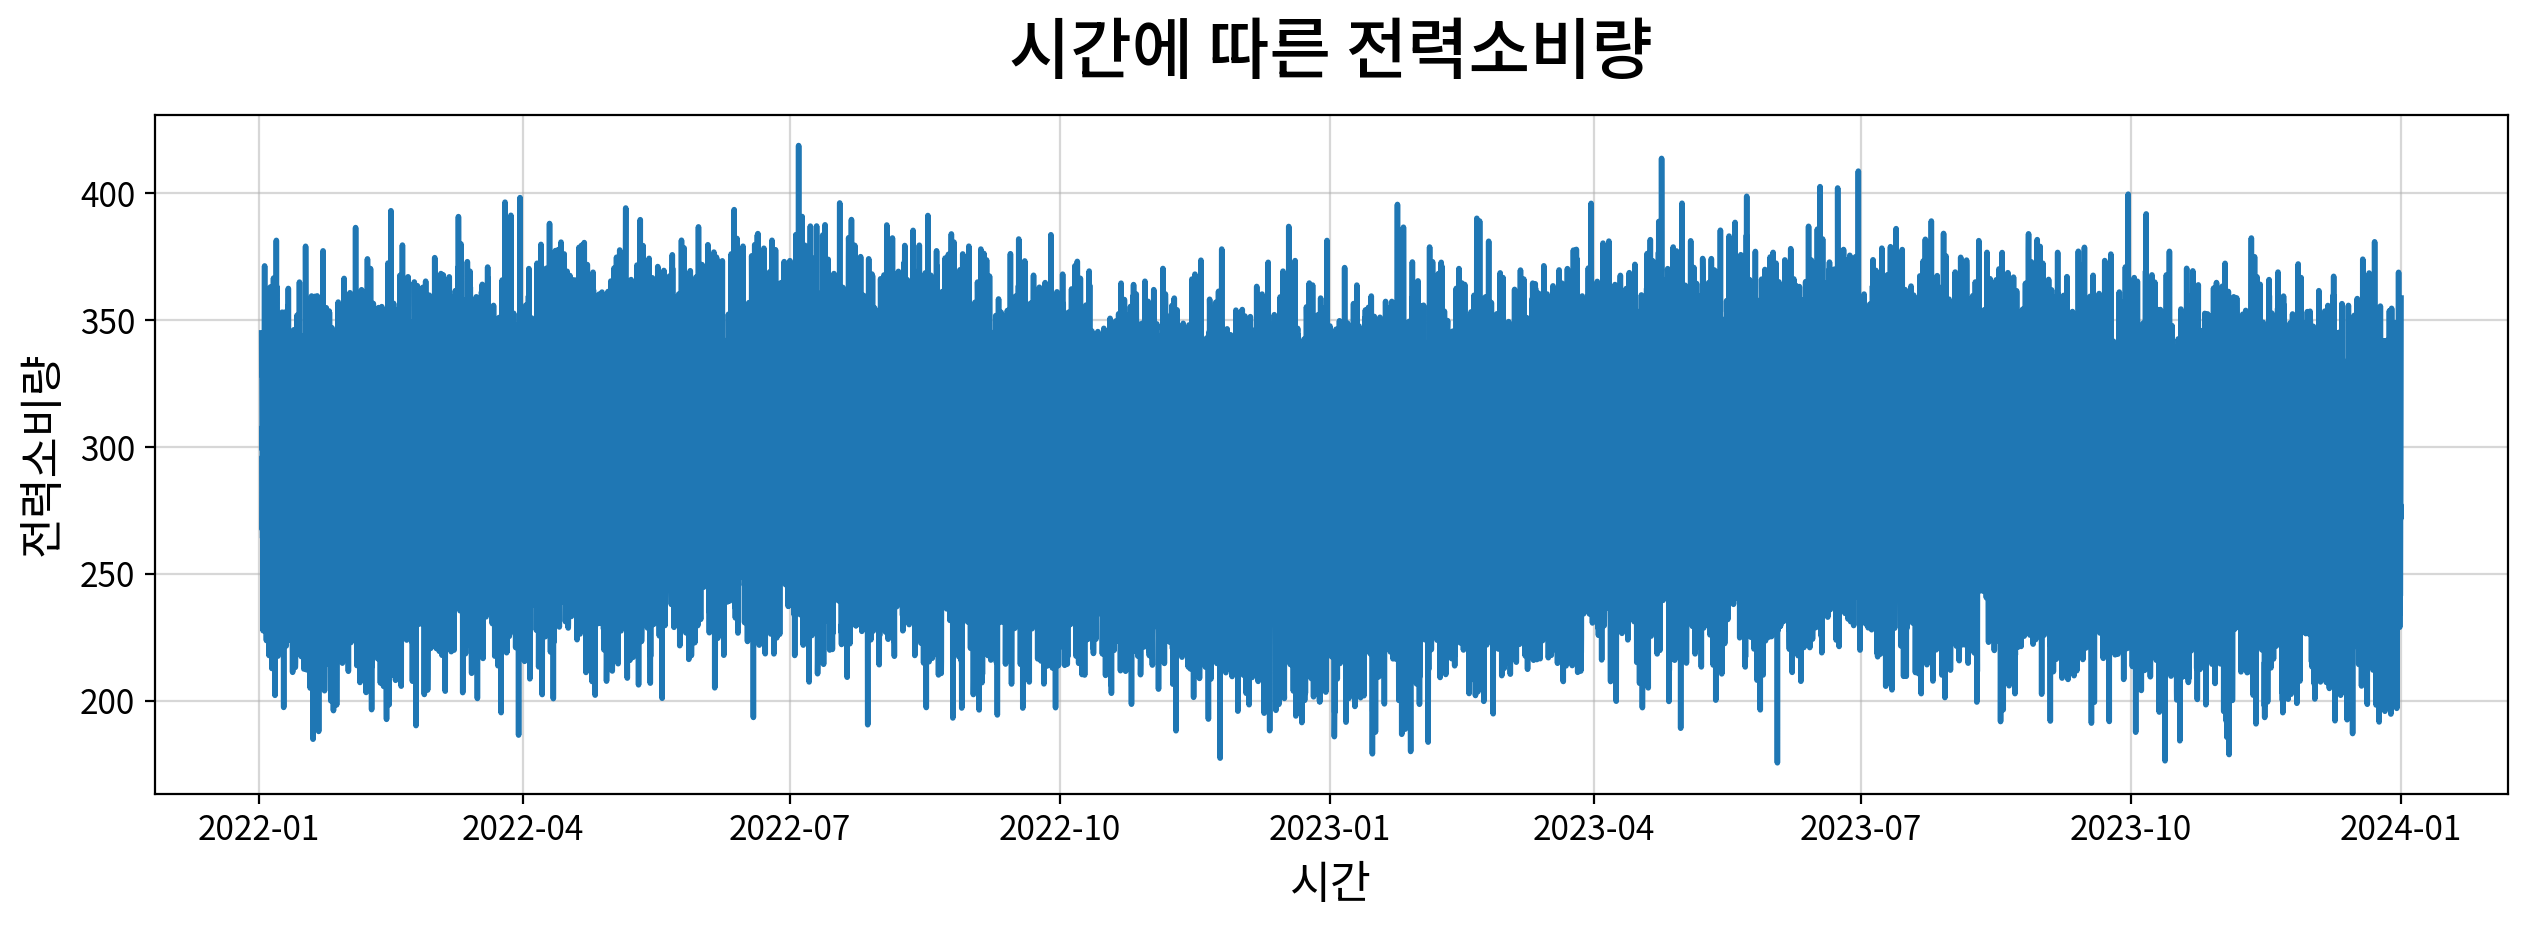

In [11]:
my_plot.lineplot(data=df1, x=df1.index, y=target,
                 title="시간에 따른 전력소비량",
                 xlabel="시간", ylabel="전력소비량",
                 width=1280, height=480)

### 2-2) 일별, 월별, 계절별 패턴 확인

In [12]:
# 일별, 월별, 계절별 리스트
my_ts.report_variation(target, freq="D")

표준편차 최대/최소 : 1.67배
변동계수 최대/최소 : 1.77배
판정: 변동폭이 일정하다 → 원본 사용 가능 / 가법(additive) 모델


,평균,표준편차,변동계수
기간,,,
2022-01-02,287.006,34.757,0.1211
2022-01-03,284.102,42.848,0.1508
2022-01-04,286.805,48.078,0.1676
2022-01-05,283.768,32.204,0.1135
2022-01-06,282.075,45.620,0.1617
...,...,...,...
2023-12-27,283.065,39.263,0.1387
2023-12-28,288.035,46.958,0.1630
2023-12-29,274.403,43.465,0.1584


In [13]:
my_ts.report_variation(target, freq="ME")

표준편차 최대/최소 : 1.08배
변동계수 최대/최소 : 1.13배
판정: 변동폭이 일정하다 → 원본 사용 가능 / 가법(additive) 모델


,평균,표준편차,변동계수
기간,,,
2022-01-31,282.764,40.574,0.1435
2022-02-28,285.915,41.409,0.1448
2022-03-31,290.806,40.613,0.1397
2022-04-30,295.340,40.197,0.1361
2022-05-31,297.344,40.305,0.1356
2022-06-30,297.395,38.616,0.1298
2022-07-31,296.962,40.606,0.1367
2022-08-31,294.034,41.885,0.1424
2022-09-30,288.950,41.055,0.1421


In [14]:
my_ts.report_variation(target, freq="QE")

표준편차 최대/최소 : 1.04배
변동계수 최대/최소 : 1.08배
판정: 변동폭이 일정하다 → 원본 사용 가능 / 가법(additive) 모델


,평균,표준편차,변동계수
기간,,,
2022-03-31,286.556,40.971,0.1430
2022-06-30,296.700,39.713,0.1338
2022-09-30,293.363,41.300,0.1408
2022-12-31,283.494,40.569,0.1431
2023-03-31,286.138,40.462,0.1414
2023-06-30,296.381,40.634,0.1371
2023-09-30,293.174,40.686,0.1388
2023-12-31,283.432,40.928,0.1444


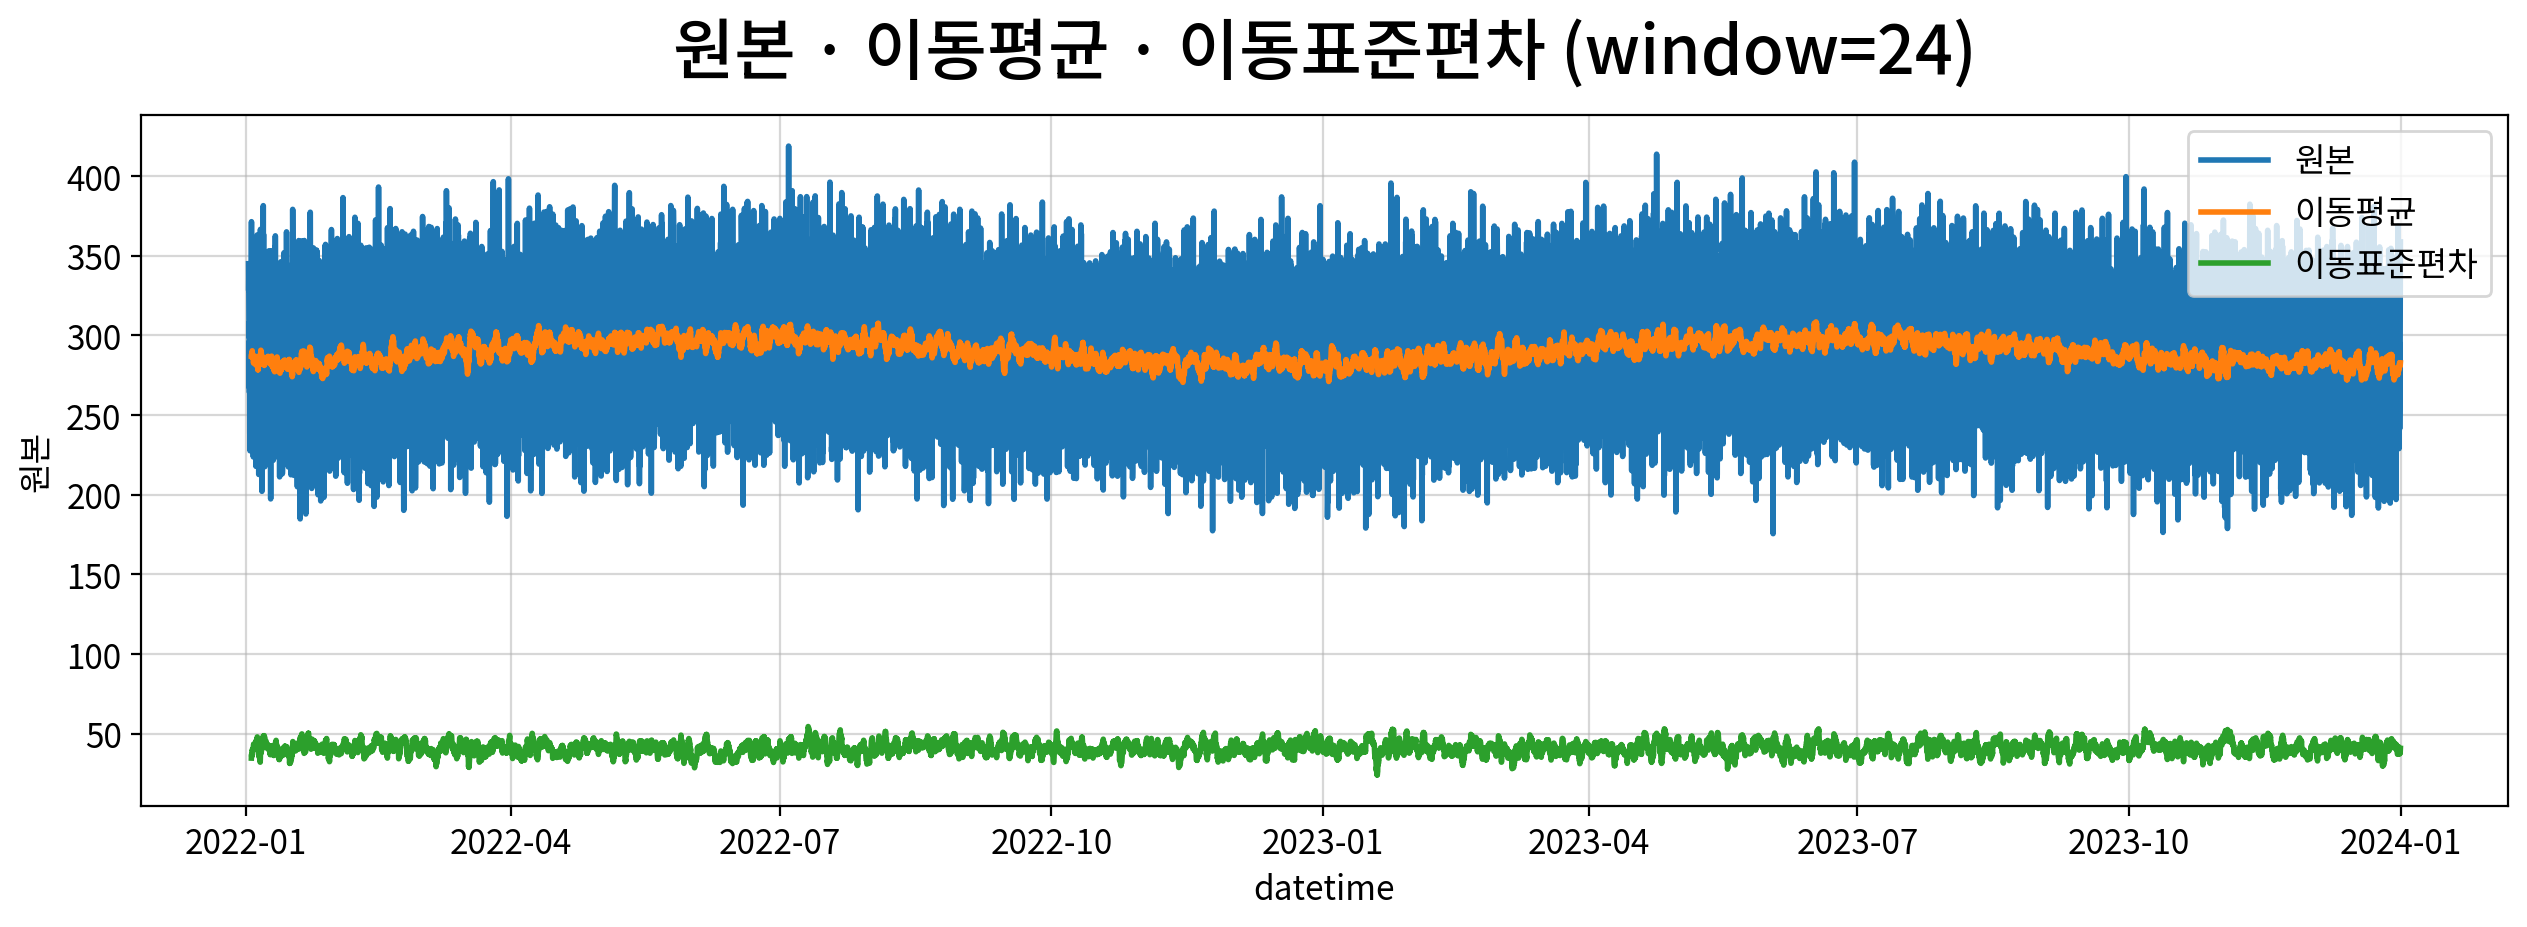

,원본,이동평균,이동표준편차
datetime,,,
2022-01-02 00:00:00,345.002816,NaN,NaN
2022-01-02 01:00:00,328.187143,NaN,NaN
2022-01-02 02:00:00,336.269392,NaN,NaN
2022-01-02 03:00:00,305.035233,NaN,NaN
2022-01-02 04:00:00,299.085592,NaN,NaN
...,...,...,...
2023-12-31 19:00:00,277.396662,281.868058,37.992945
2023-12-31 20:00:00,271.725090,280.963946,37.964168
2023-12-31 21:00:00,304.078170,280.654992,37.734396


In [15]:
# 추세 확인
my_ts.plot_rolling(target, window=24)

결합 방식 자동 판정: additive
관측치 17496개 중 추세·잔차가 계산된 구간 17472개


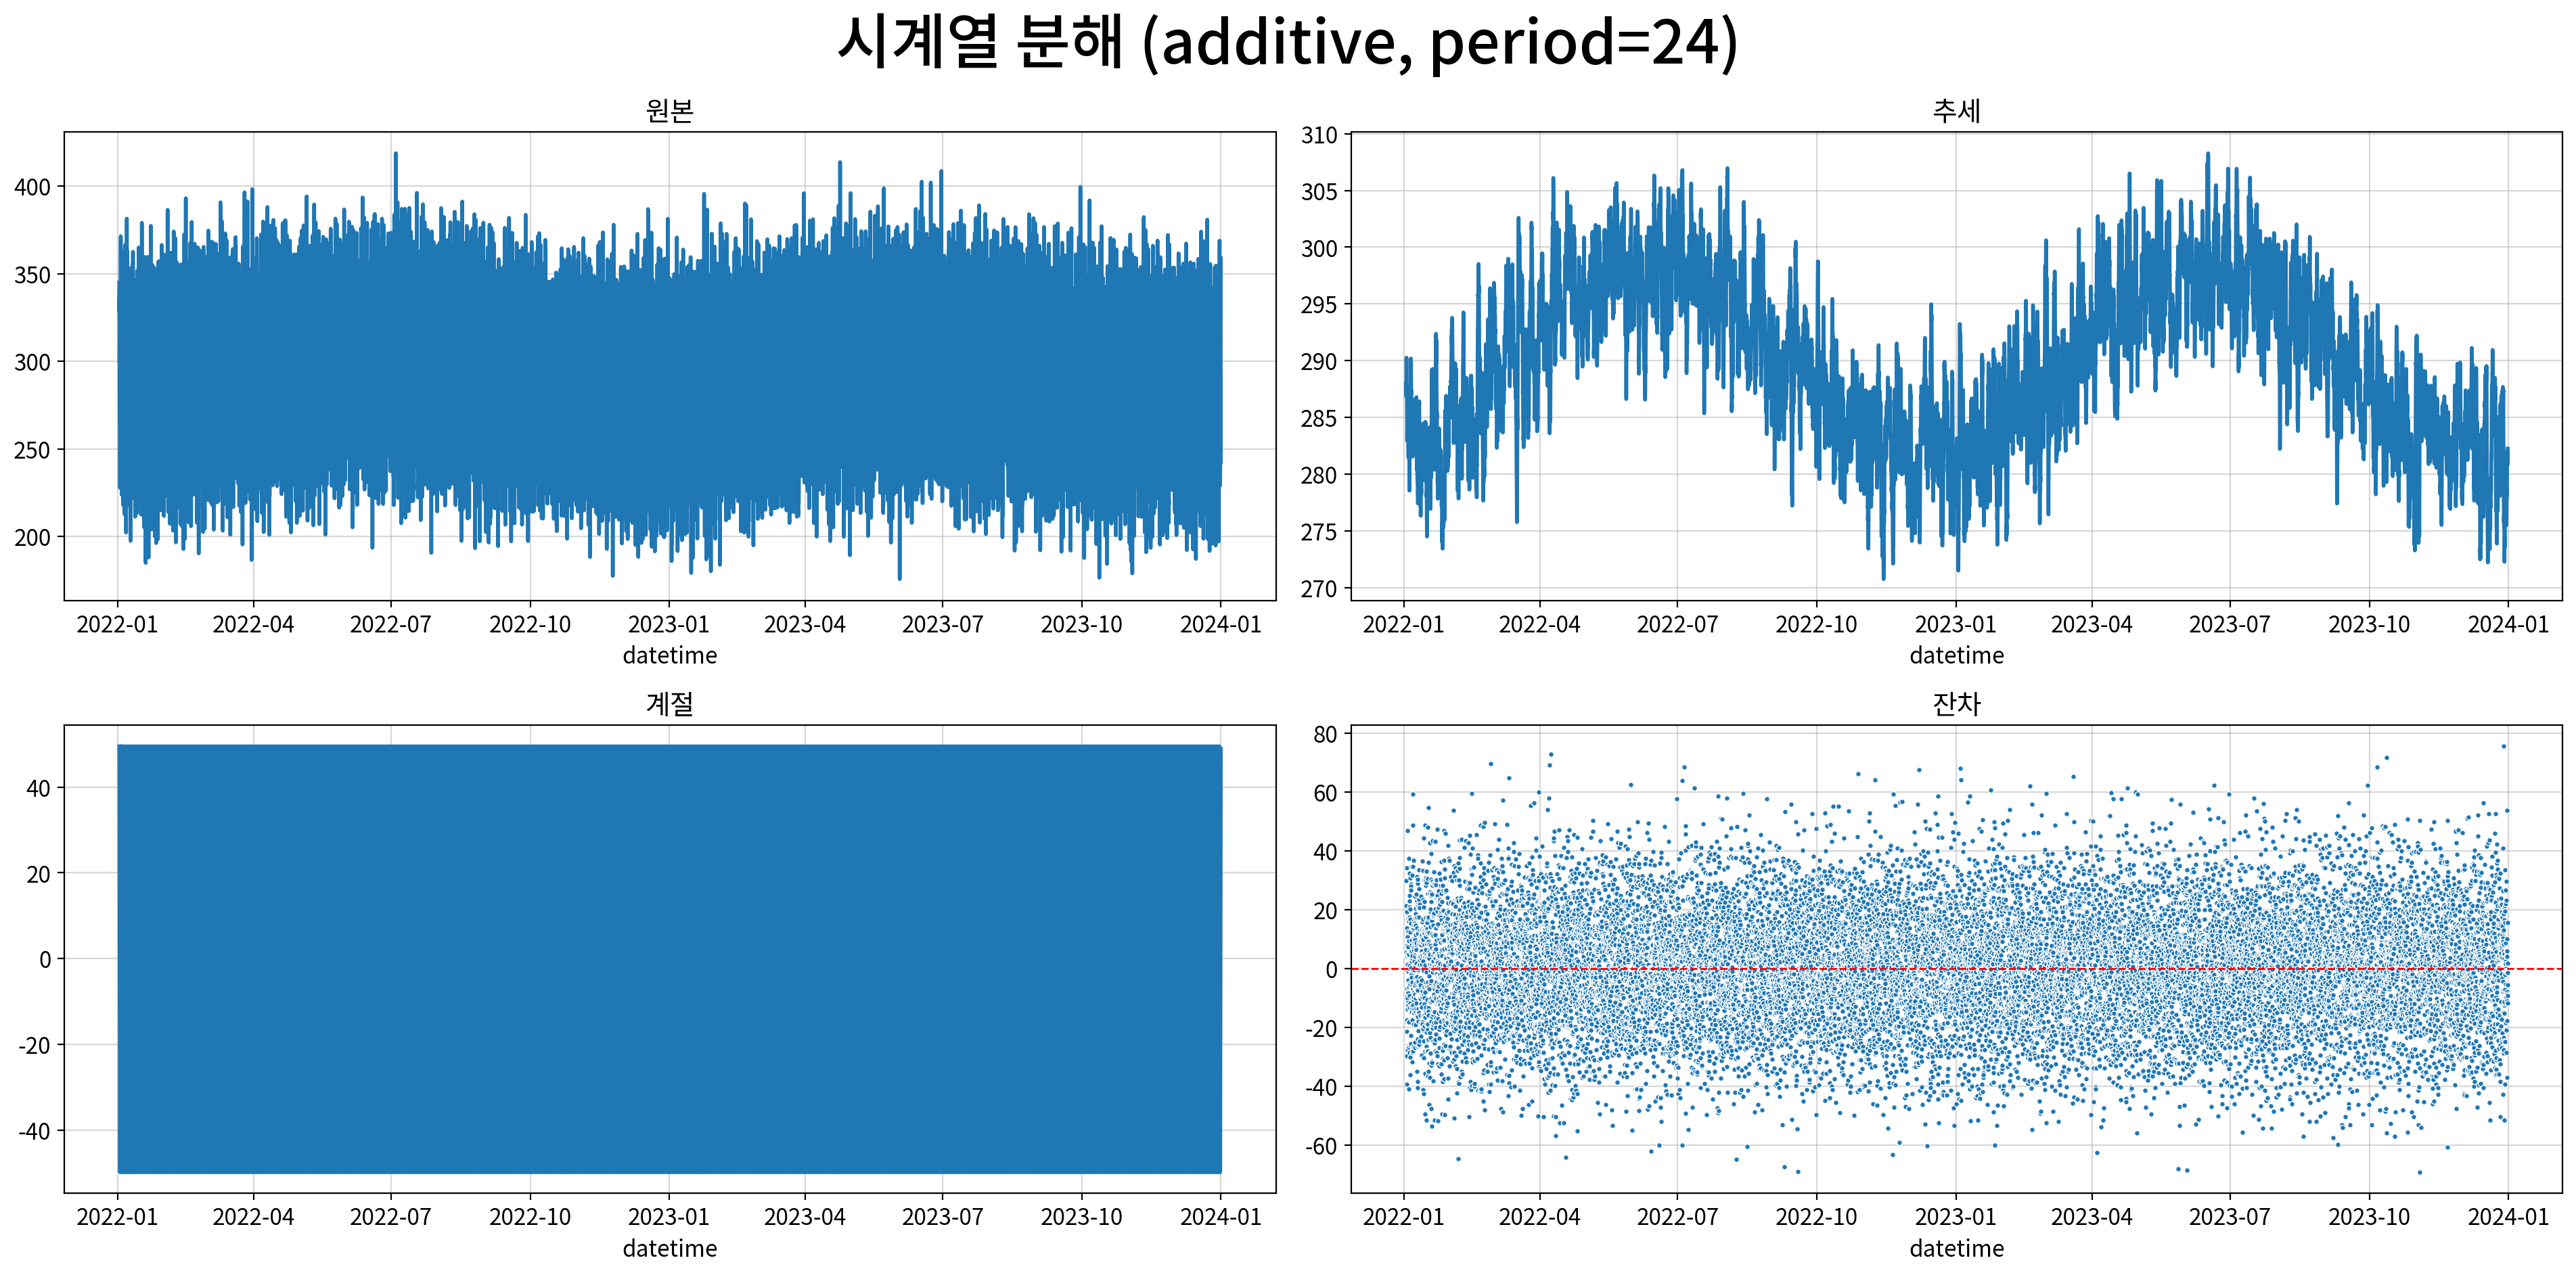

,원본,추세,계절,잔차
datetime,,,,
2022-01-02 00:00:00,345.002816,NaN,49.539424,NaN
2022-01-02 01:00:00,328.187143,NaN,46.916358,NaN
2022-01-02 02:00:00,336.269392,NaN,43.490010,NaN
2022-01-02 03:00:00,305.035233,NaN,34.236756,NaN
2022-01-02 04:00:00,299.085592,NaN,24.725611,NaN
...,...,...,...,...
2023-12-31 19:00:00,277.396662,NaN,12.348682,NaN
2023-12-31 20:00:00,271.725090,NaN,25.665681,NaN
2023-12-31 21:00:00,304.078170,NaN,34.289109,NaN


In [16]:
# 추세·계절·잔차 분해: 일주기
my_ts.decompose(target, period=24)

결합 방식 : additive
최고 위치 : 1 (49.5394)
최저 위치 : 13 (-49.8441)


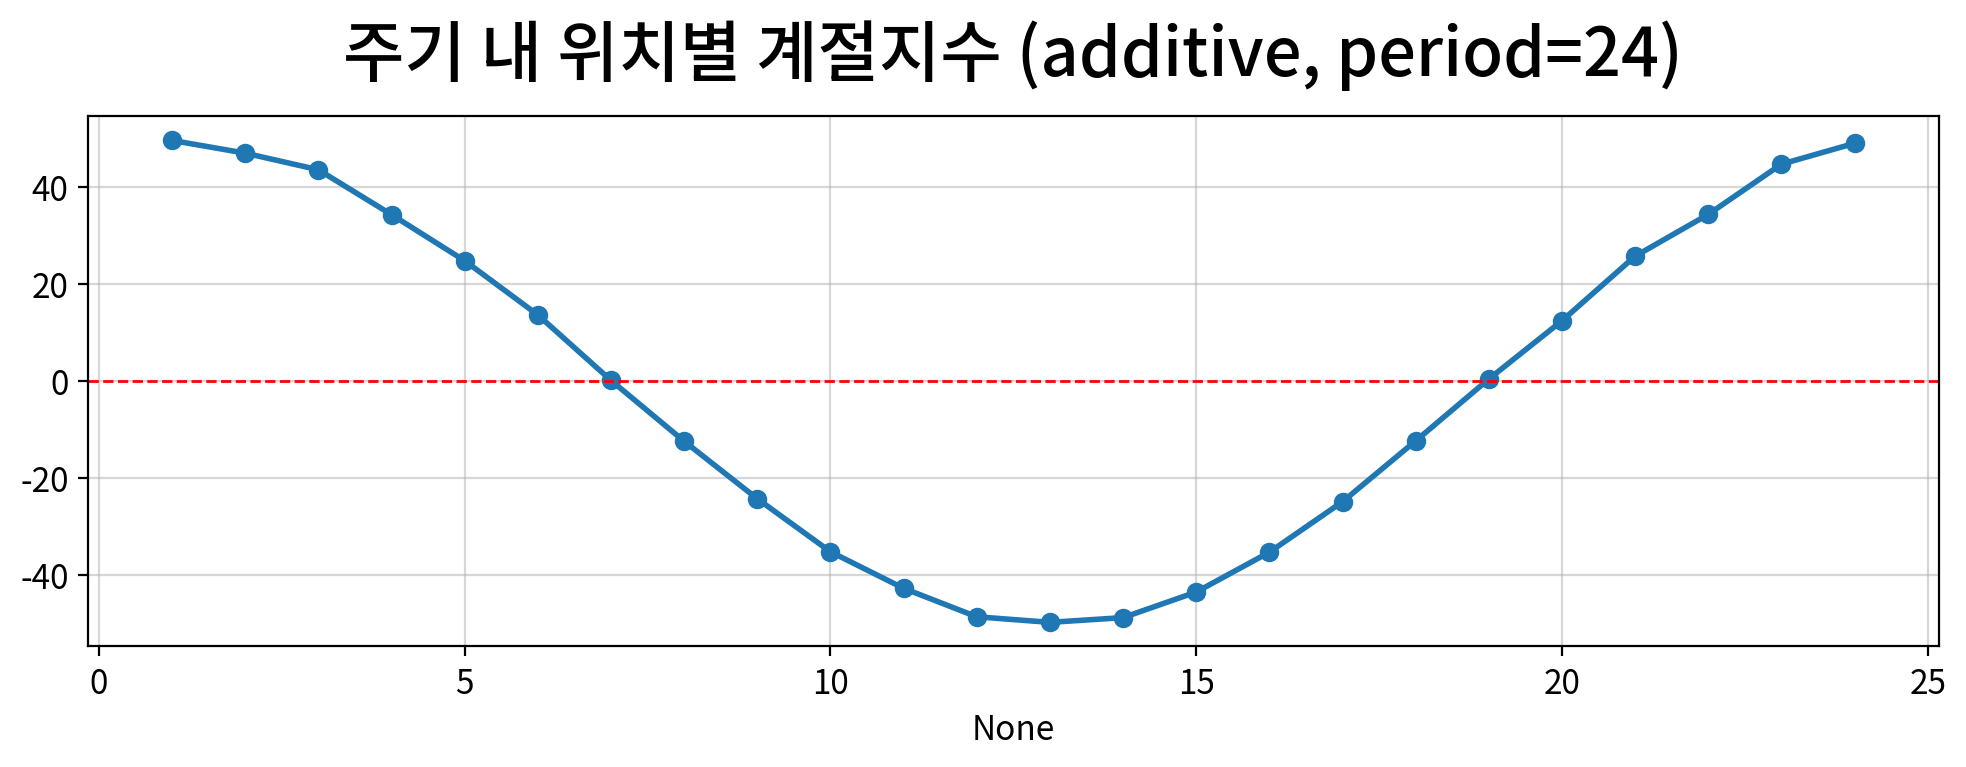

,계절지수,평균,기준 대비
주기 내 위치,,,
1,49.5394,0.0,49.539
2,46.9164,0.0,46.916
3,43.4900,0.0,43.490
4,34.2368,0.0,34.237
5,24.7256,0.0,24.726
6,13.5543,0.0,13.554
7,0.0553,0.0,0.055
8,-12.4930,0.0,-12.493
9,-24.3560,0.0,-24.356


In [17]:
# 시간대별 계절성
my_ts.report_seasonal(target, period=24)

결합 방식 : additive
최고 위치 : 72 (53.1467)
최저 위치 : 13 (-52.2351)


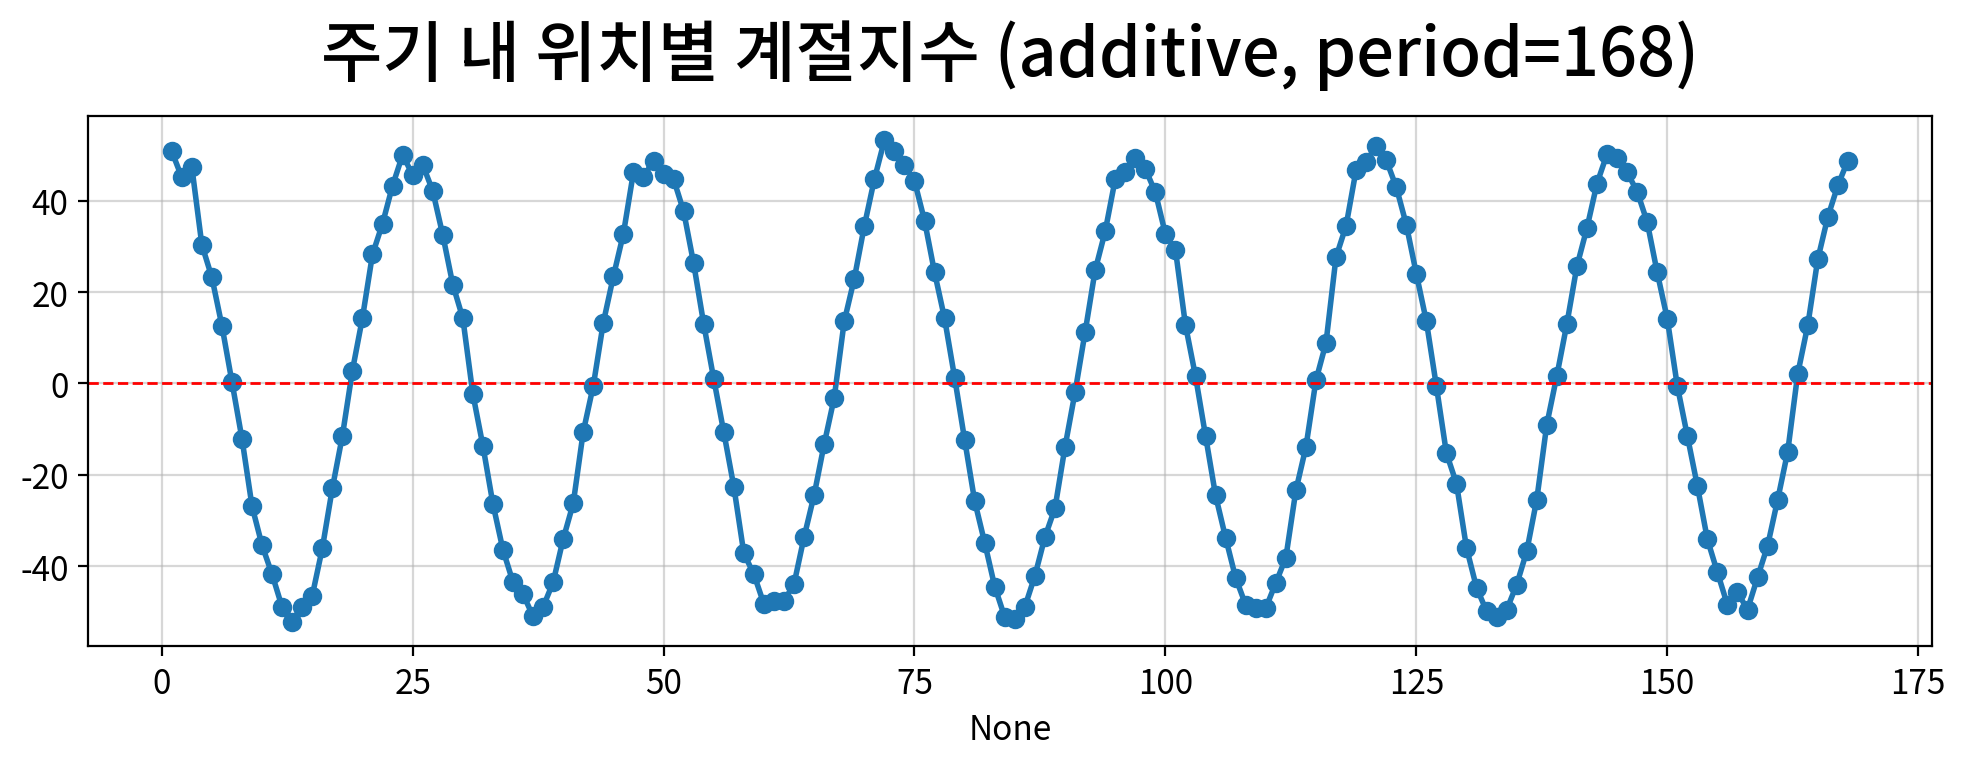

,계절지수,평균,기준 대비
주기 내 위치,,,
1,50.7590,0.0,50.759
2,45.0897,0.0,45.090
3,47.3554,0.0,47.355
4,30.3223,0.0,30.322
5,23.1817,0.0,23.182
...,...,...,...
164,12.7010,0.0,12.701
165,27.1742,0.0,27.174
166,36.4173,0.0,36.417


In [18]:
# 주간 계절성
my_ts.report_seasonal(target, period=168)

관측치 17496개 | 유의성 기준값 0.015 | 최대 시차 72 (상한 N/4=4374)
AR 차수 후보 (p): 2      ← PACF가 lag 2 이후 절단
MA 차수 후보 (q): 72      ← ACF가 lag 72 이후 절단
계절 AR 차수 후보 (P): 3          ←계절 PACF가 lag 72 이후 절단(판정 시차 [24, 48, 72])
계절 MA 차수 후보 (Q): 3          ←계절 ACF가 lag 72 이후 절단(판정 시차 [24, 48, 72])
→ SARIMA(2, d, 72)(3, D, 3)[24] - d·D 는 차분 단계의 결과를 넣는다


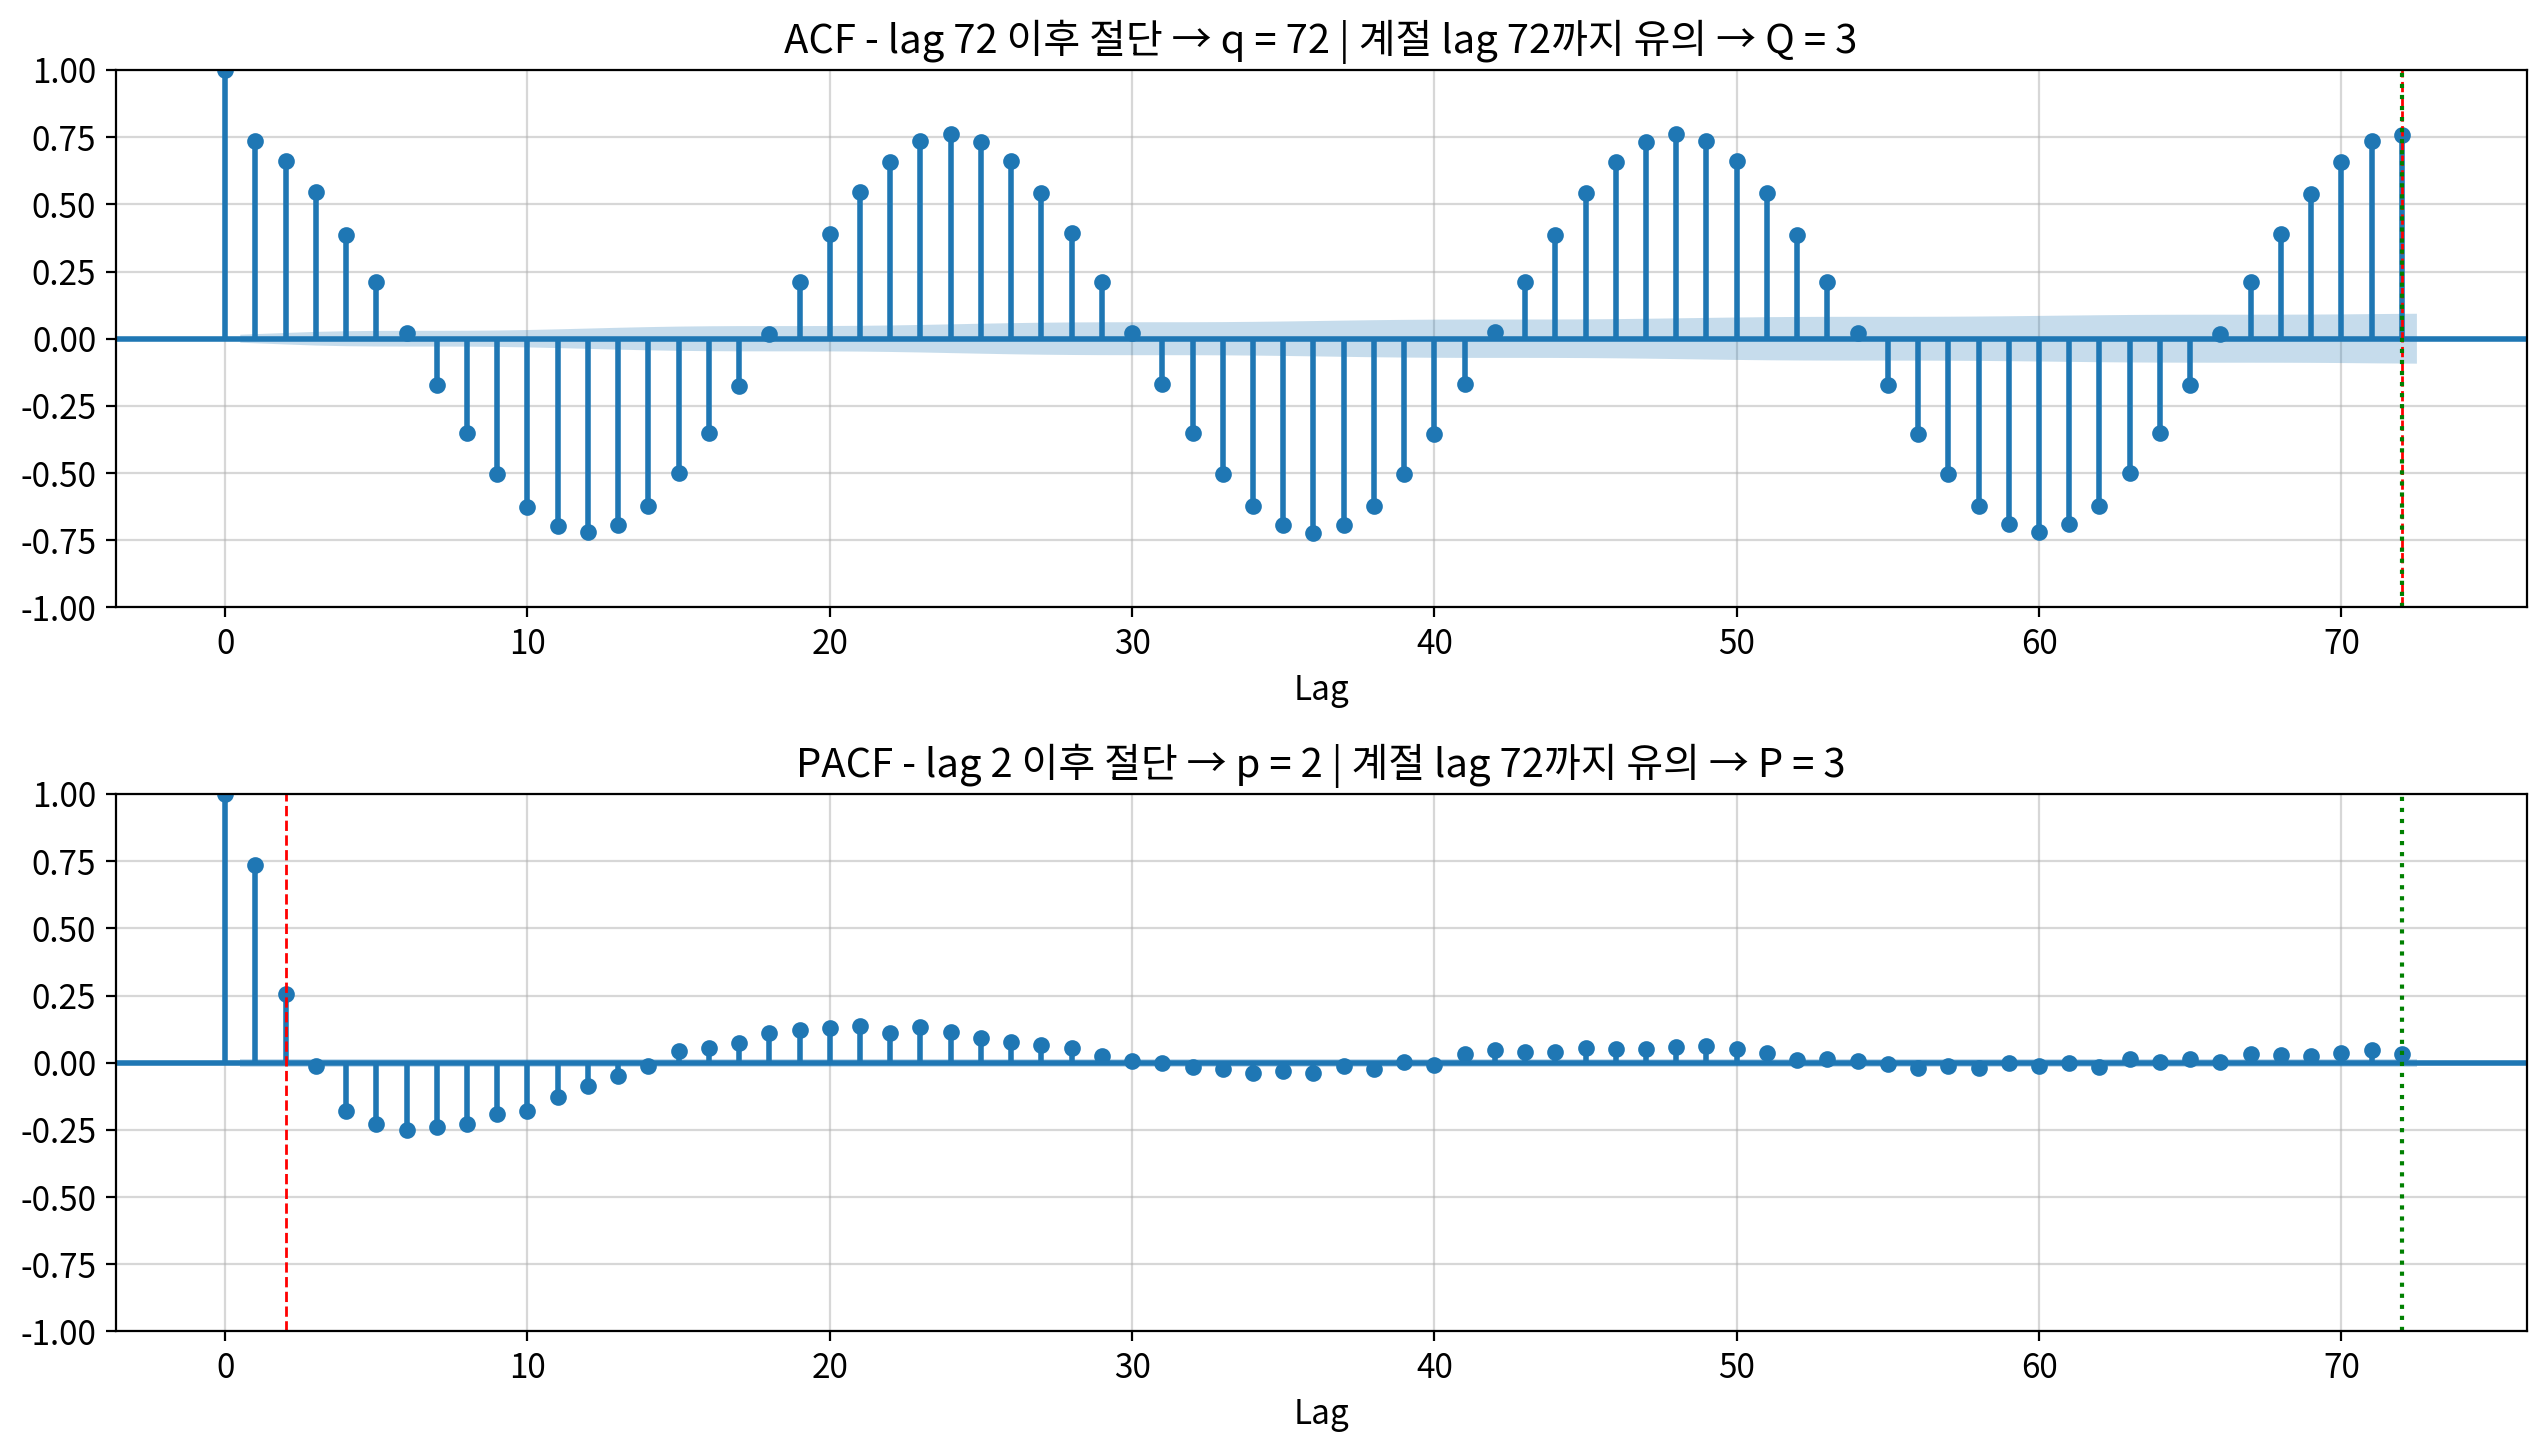

,acf,acf 유의성,pacf,pacf 유의성,기준값,p,q,P,Q
lag,,,,,,,,,
1,0.737,True,0.737,True,0.015,,,,
2,0.660,True,0.255,True,0.015,◀,,,
3,0.545,True,-0.013,False,0.015,,,,
4,0.387,True,-0.180,True,0.015,,,,
5,0.212,True,-0.228,True,0.015,,,,
...,...,...,...,...,...,...,...,...,...
68,0.389,True,0.030,True,0.015,,,,
69,0.540,True,0.030,True,0.015,,,,
70,0.659,True,0.039,True,0.015,,,,


In [19]:
# 자기상관 확인
my_ts.auto_correlation(target, period=24)

### 3) 구간을 나눠서 비교

In [20]:
my_ts.report_split(df1, column="load_demand_MW", size=4)

,시작,종료,관측치 수,평균,표준편차,변동계수
구간,,,,,,
구간 1,2022-01-02,2022-07-03,4374,291.823,40.647,0.1393
구간 2,2022-07-03,2023-01-01,4374,288.236,41.220,0.1430
구간 3,2023-01-01,2023-07-02,4374,291.308,40.816,0.1401
구간 4,2023-07-02,2023-12-31,4374,288.276,41.149,0.1427


#### 4-1-4) 시간대별·요일별 전력수요 패턴

,평균,표준편차,최소,최대
hour_of_day,,,,
0,339.46,21.48,272.48,413.75
1,336.82,20.41,276.61,408.74
2,333.41,21.50,277.03,388.11
3,324.13,20.92,244.68,391.89
4,314.62,21.49,252.73,390.84
5,303.48,20.55,238.36,372.88
6,289.94,20.88,228.17,349.78
7,277.45,20.57,215.22,347.46
8,265.55,20.95,197.16,330.64


,평균,표준편차,최소,최대
day_of_week,,,,
0,289.21,40.34,185.90,413.75
1,290.46,41.12,184.27,398.83
2,289.53,41.00,184.88,391.26
3,290.08,40.92,176.39,398.30
4,289.88,41.59,175.60,408.74
5,290.29,40.50,180.06,402.62
6,289.92,41.48,179.13,418.82


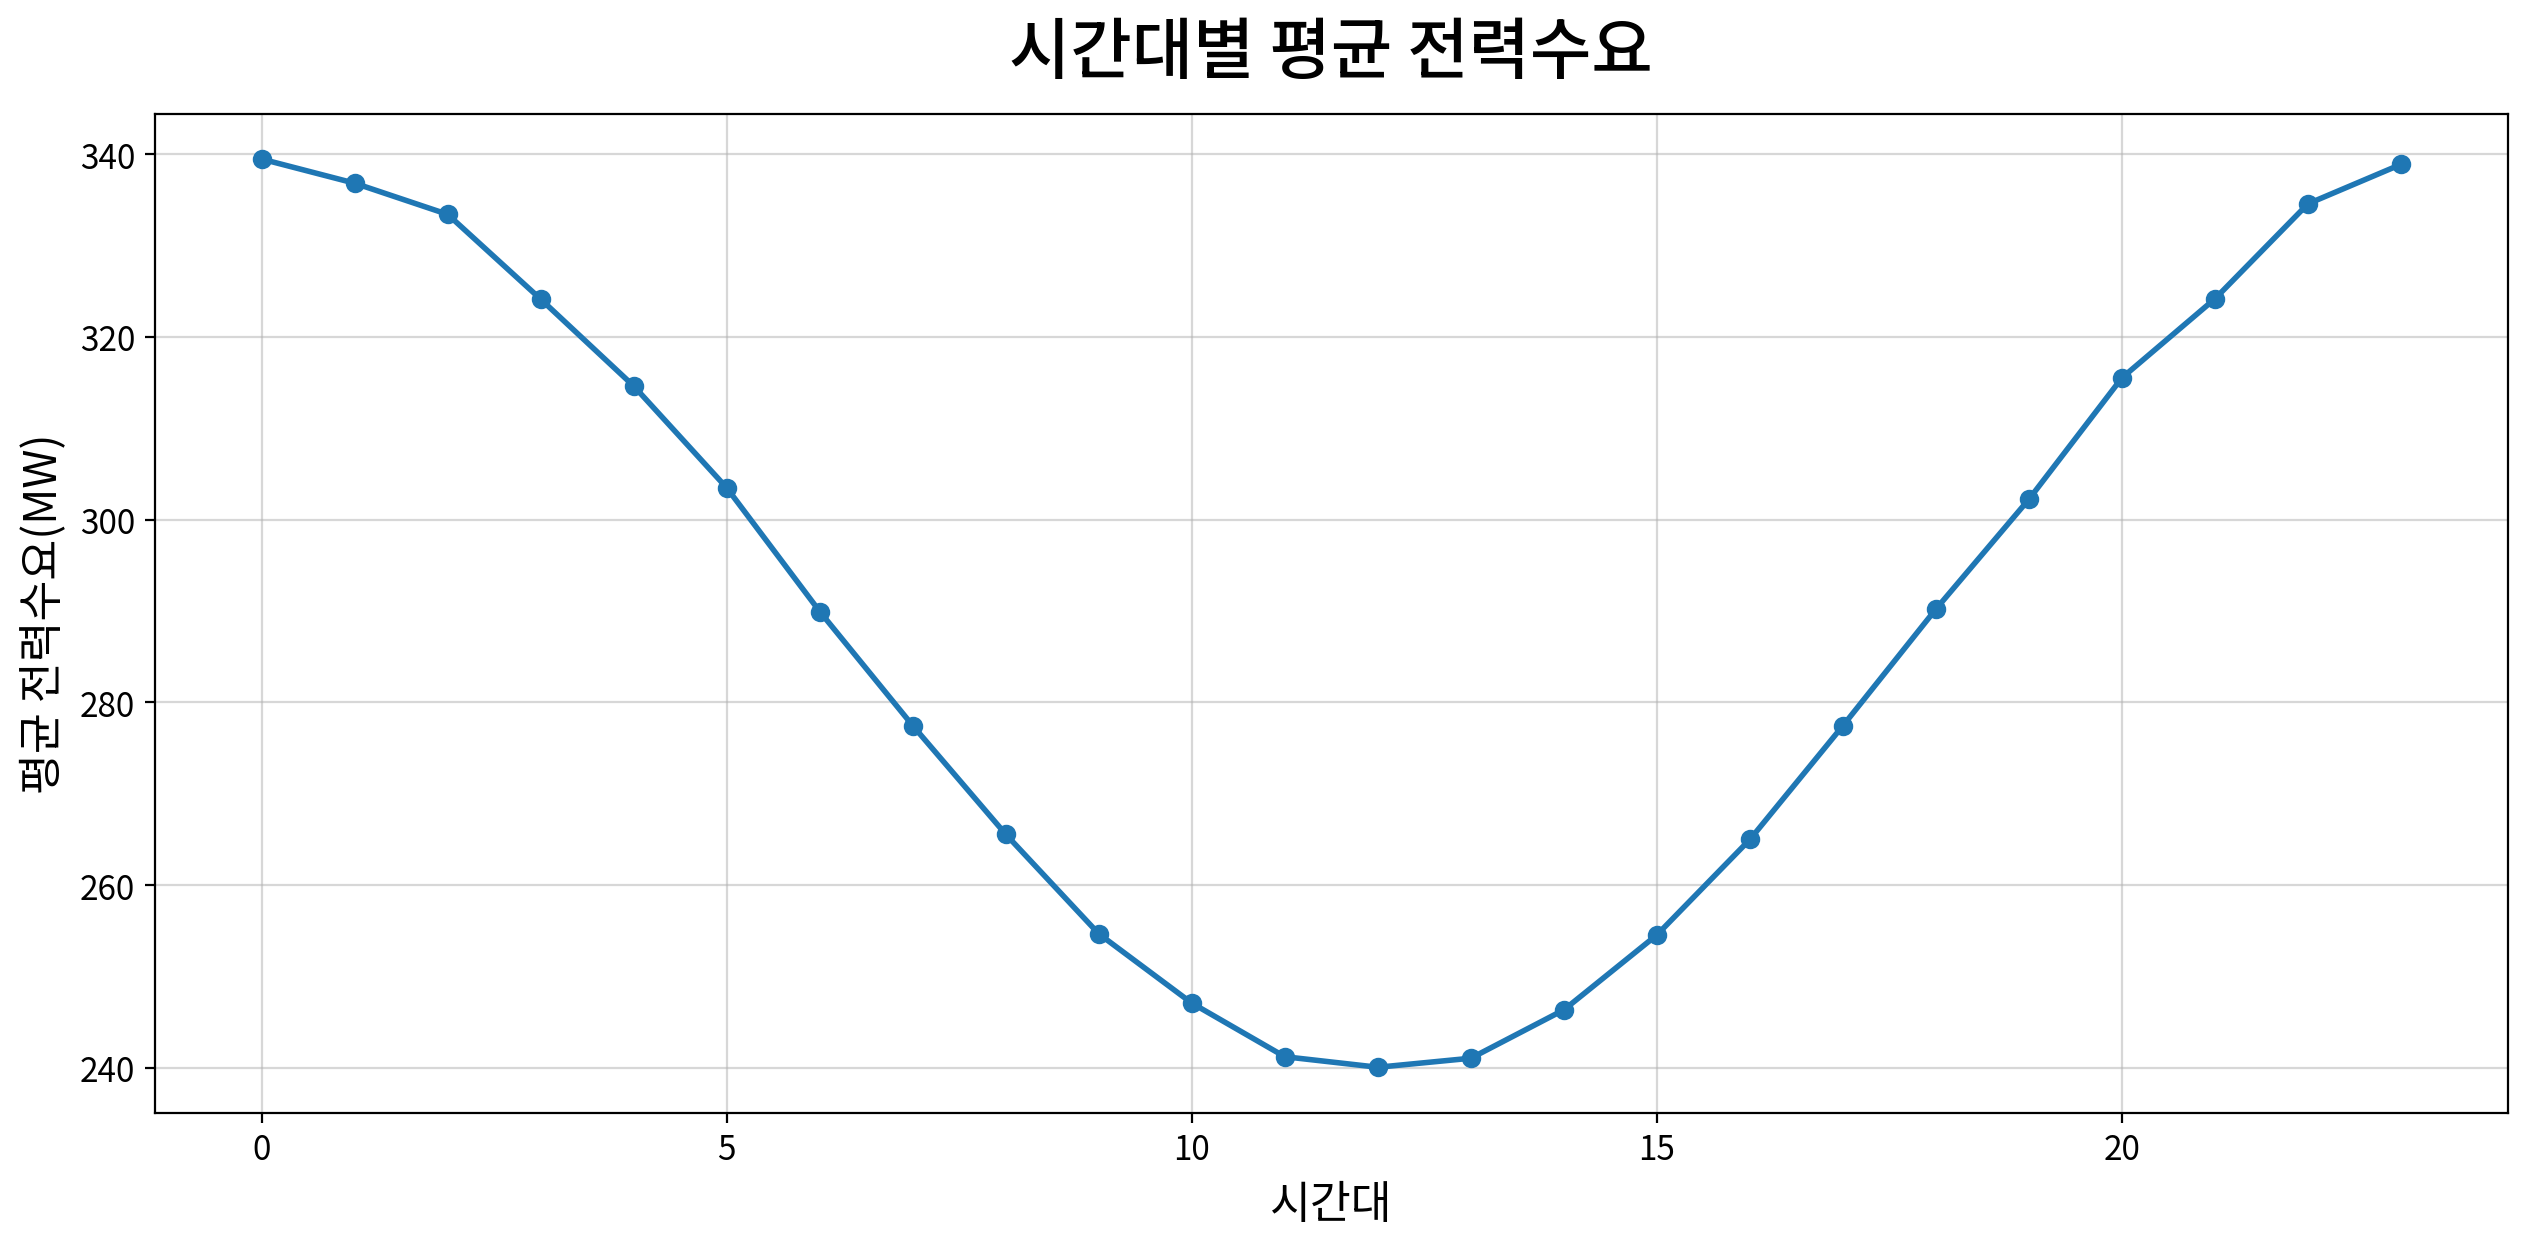

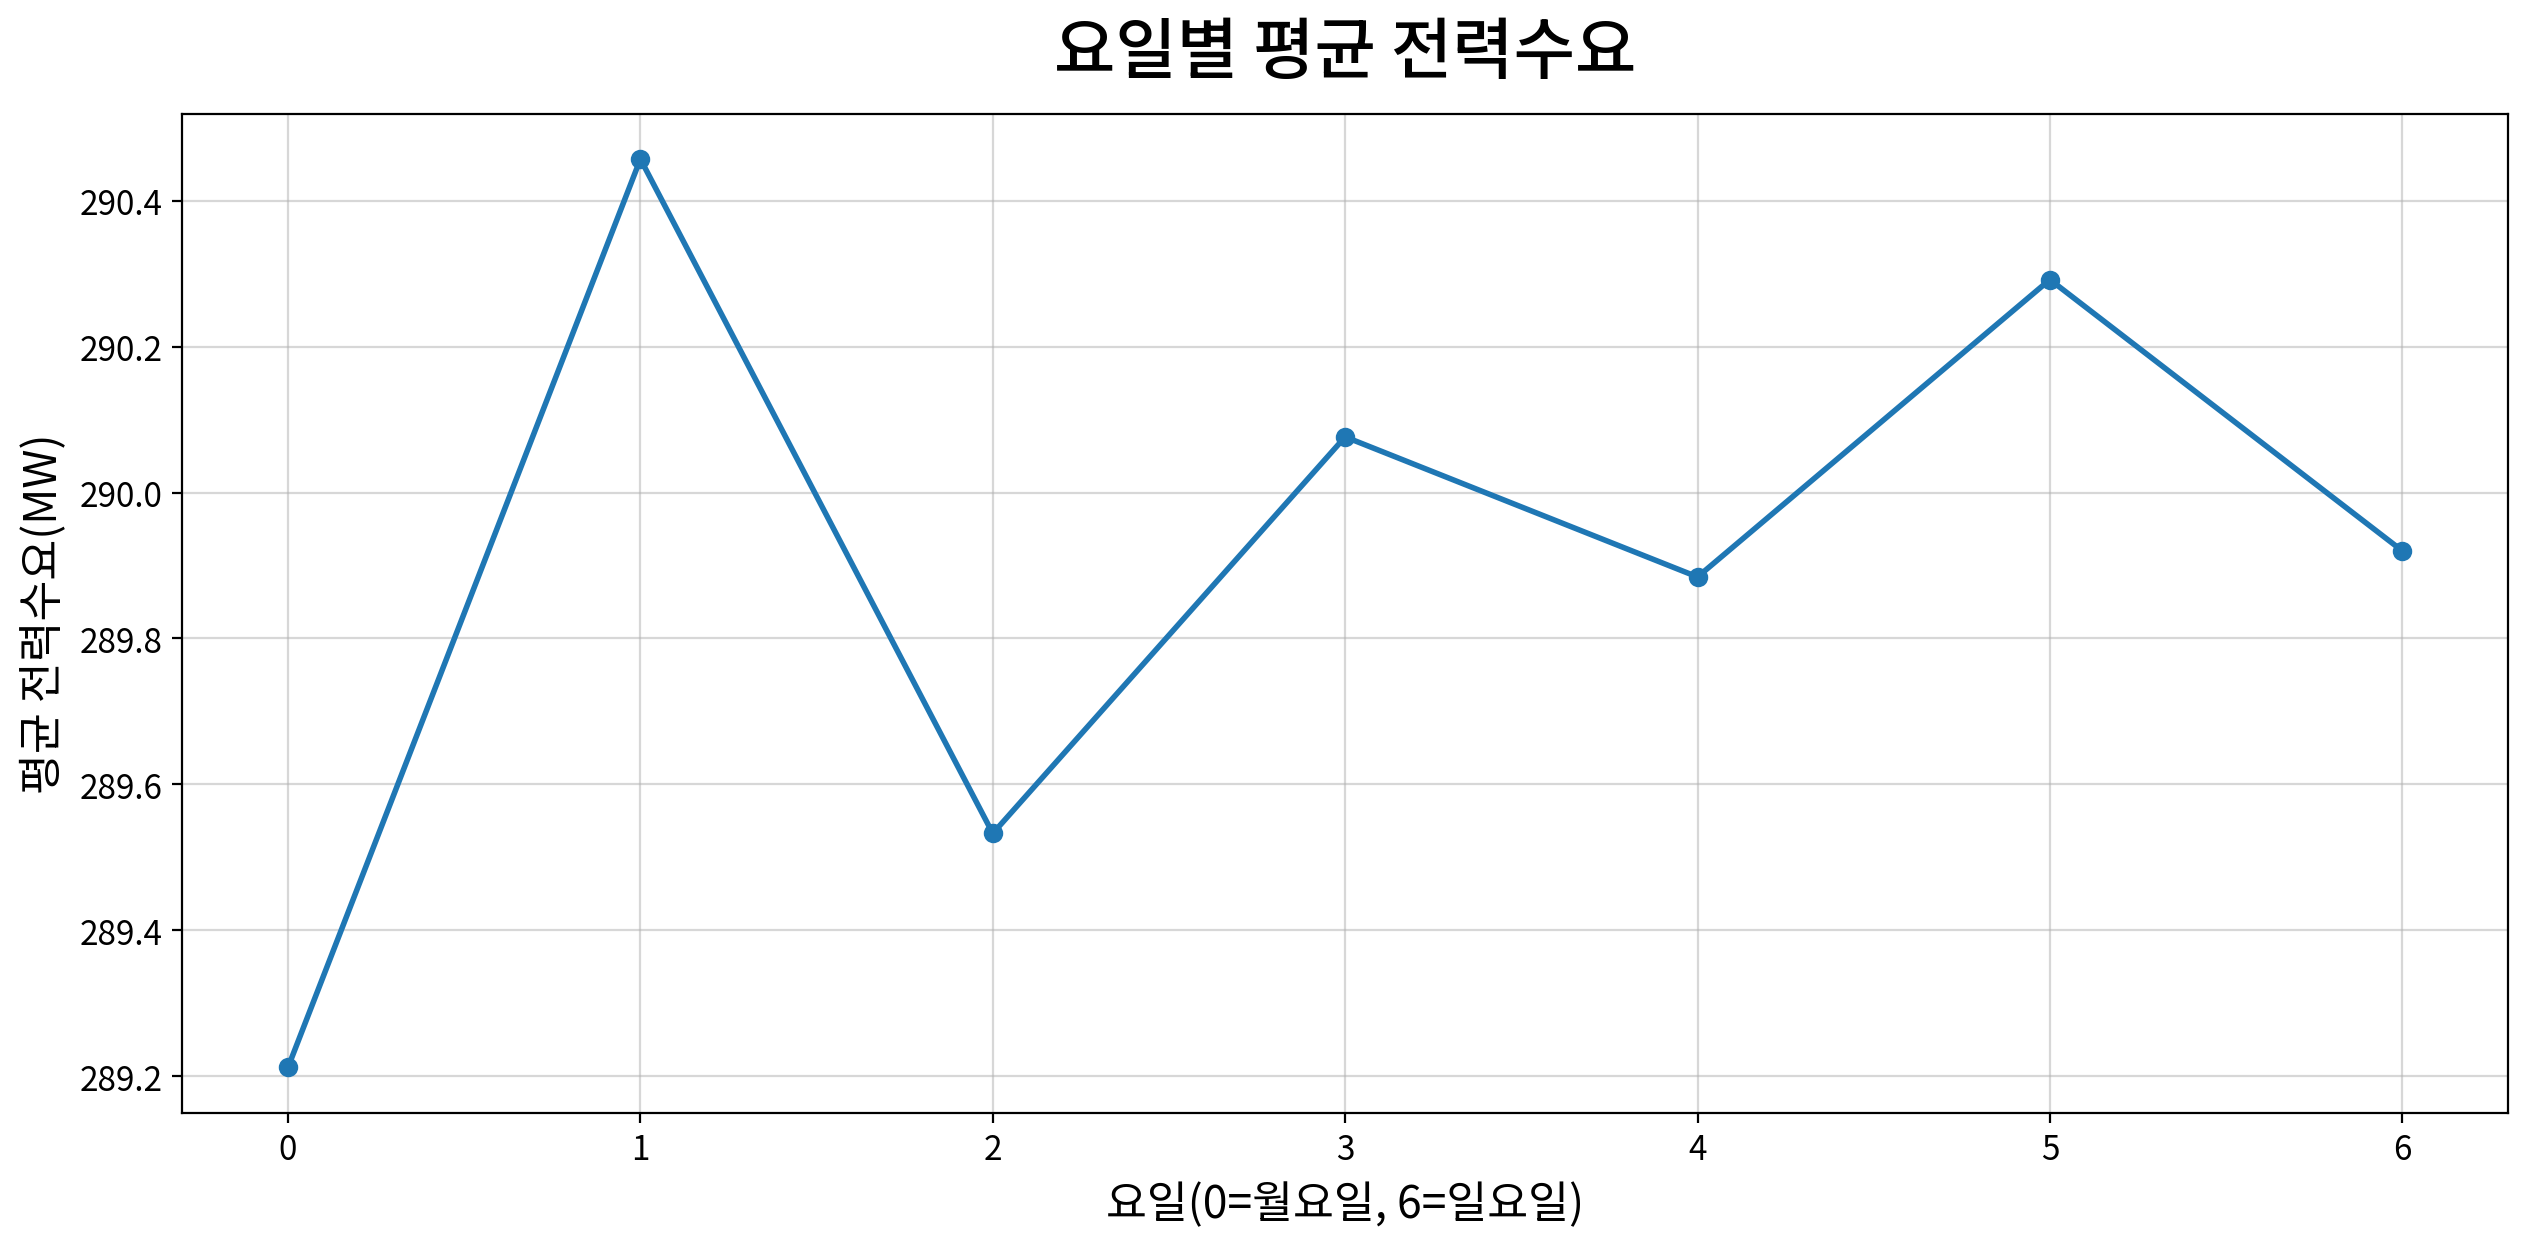

In [25]:
hourly_pattern = df1.groupby("hour_of_day")["load_demand_MW"].agg(["mean", "std", "min", "max"])
daily_pattern = df1.groupby("day_of_week")["load_demand_MW"].agg(["mean", "std", "min", "max"])

hourly_pattern.columns = ["평균", "표준편차", "최소", "최대"]
daily_pattern.columns = ["평균", "표준편차", "최소", "최대"]

display(hourly_pattern.round(2))
display(daily_pattern.round(2))

my_plot.lineplot(
    data=hourly_pattern.reset_index(),
    x="hour_of_day", y="평균", marker="o",
    title="시간대별 평균 전력수요",
    xlabel="시간대", ylabel="평균 전력수요(MW)"
)

my_plot.lineplot(
    data=daily_pattern.reset_index(),
    x="day_of_week", y="평균", marker="o",
    title="요일별 평균 전력수요",
    xlabel="요일(0=월요일, 6=일요일)", ylabel="평균 전력수요(MW)"
)

#### 4-1-5) 계절별 전력수요 패턴

,평균,표준편차,최소,최대
season,,,,
Spring,294.02,40.46,186.52,413.75
Summer,296.12,40.53,175.60,418.82
Autumn,285.72,40.61,176.39,399.66
Winter,283.57,41.00,179.13,395.62


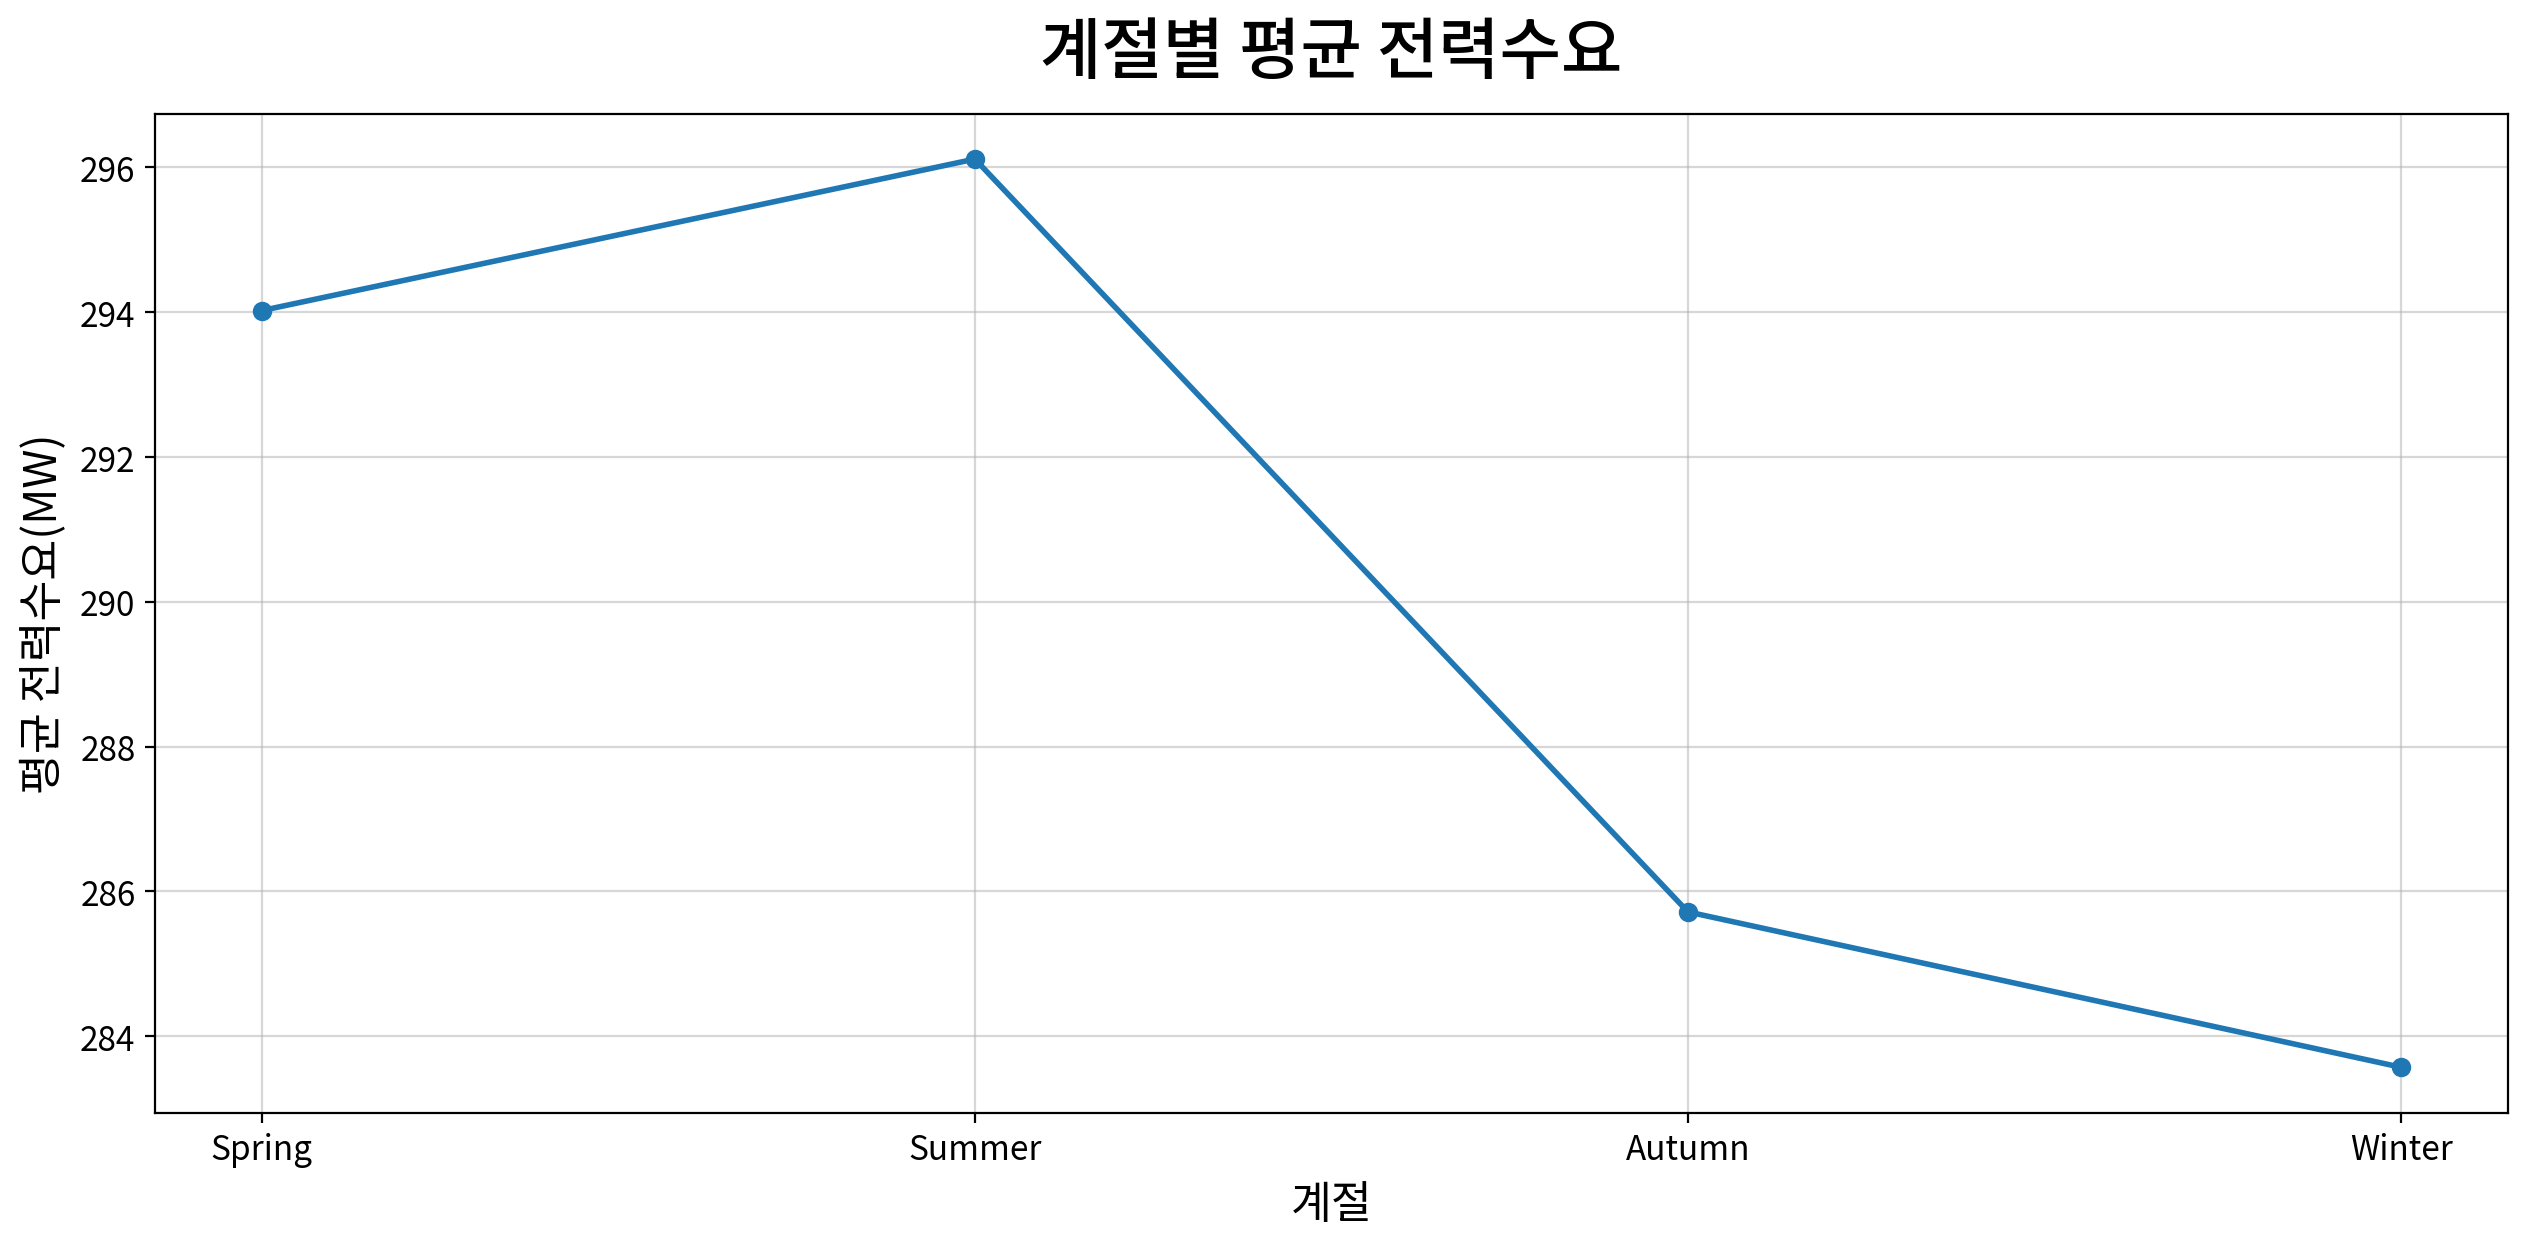

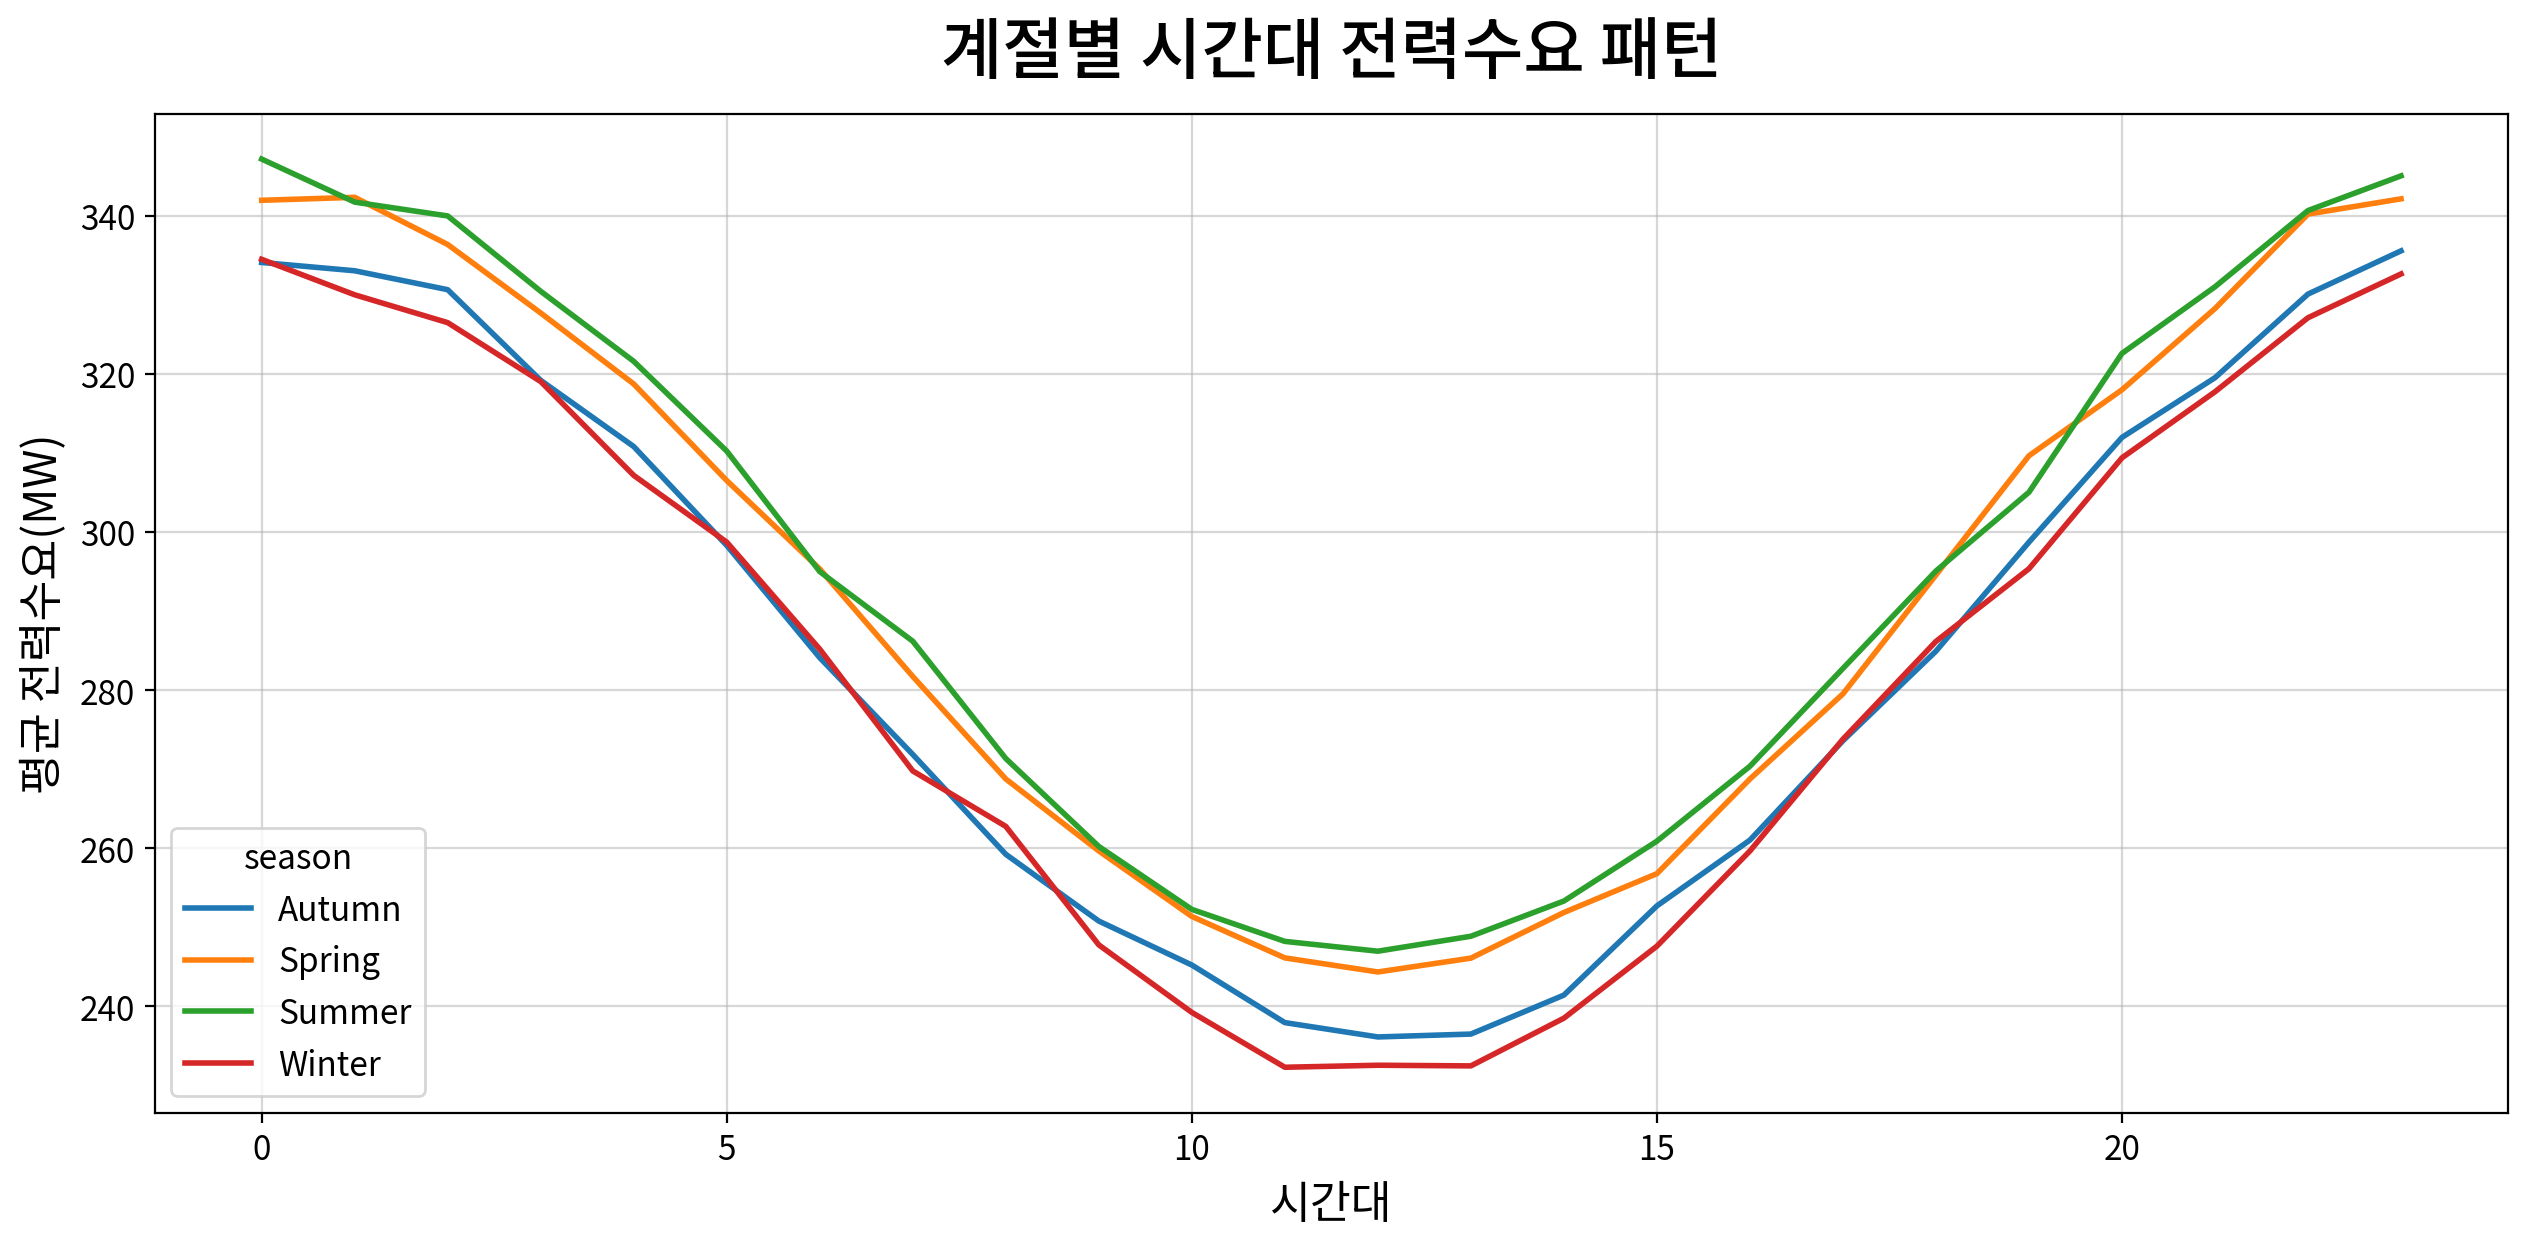

In [31]:
season_pattern = df1.groupby("season")["load_demand_MW"].agg(["mean", "std", "min", "max"])
season_order = ["Spring", "Summer", "Autumn", "Winter"]
season_pattern = season_pattern.reindex([s for s in season_order if s in season_pattern.index])
season_pattern.columns = ["평균", "표준편차", "최소", "최대"]

display(season_pattern.round(2))

my_plot.lineplot(
    data=season_pattern.reset_index(),
    x="season", y="평균", marker="o",
    title="계절별 평균 전력수요",
    xlabel="계절", ylabel="평균 전력수요(MW)"
)

season_hour_pattern = (
    df1.groupby(["season", "hour_of_day"], observed=True)["load_demand_MW"]
       .mean()
       .reset_index()
)

my_plot.lineplot(
    data=season_hour_pattern,
    x="hour_of_day", y="load_demand_MW", hue="season",
    title="계절별 시간대 전력수요 패턴",
    xlabel="시간대", ylabel="평균 전력수요(MW)"
)

#### 4-1-6) 이동평균과 이동표준편차로 추세·변동성 확인

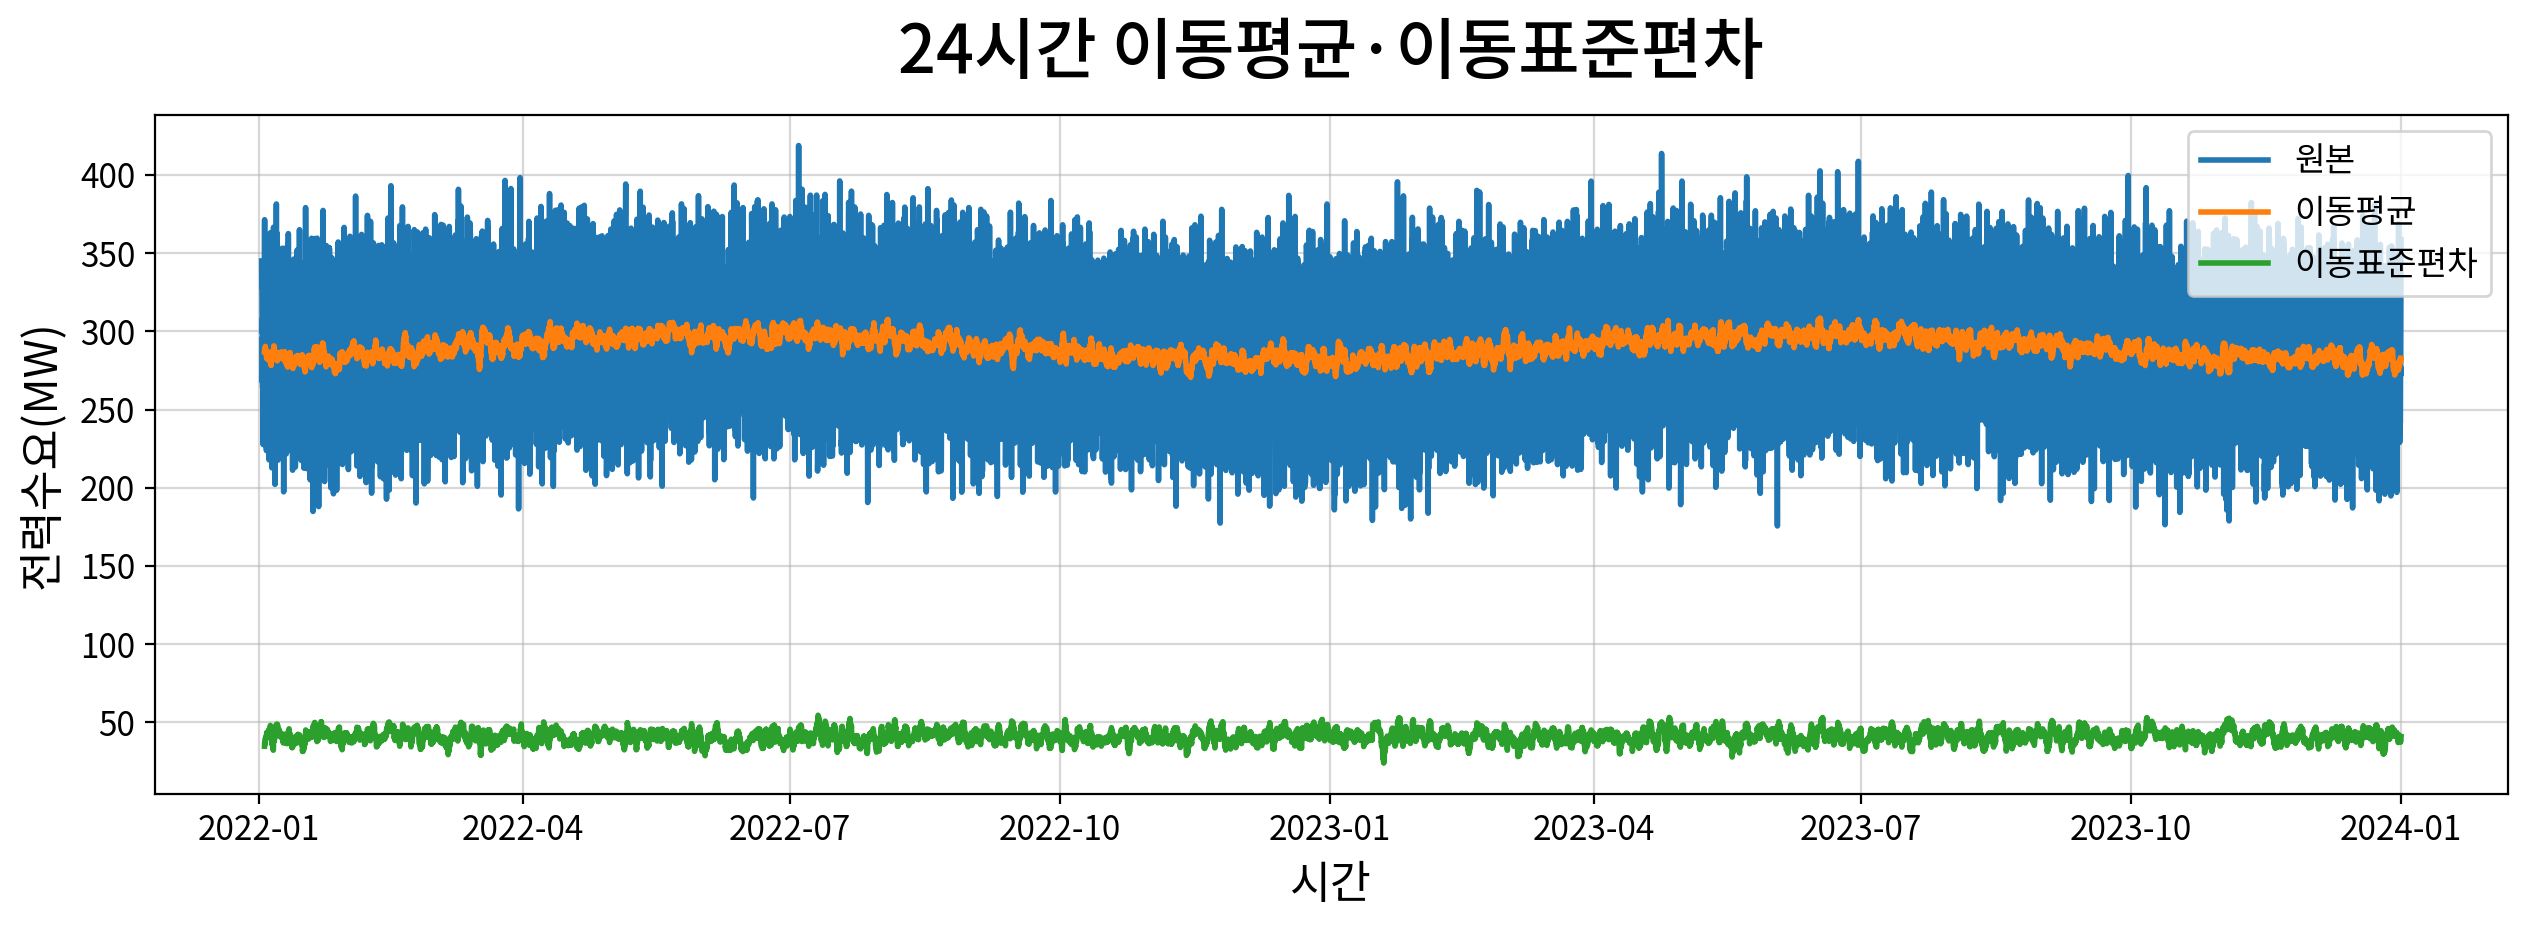

,원본,이동평균,이동표준편차
datetime,,,
2023-12-31 19:00:00,277.396662,281.868058,37.992945
2023-12-31 20:00:00,271.725090,280.963946,37.964168
2023-12-31 21:00:00,304.078170,280.654992,37.734396
2023-12-31 22:00:00,340.431919,281.719436,39.078361
2023-12-31 23:00:00,358.725993,282.793732,40.861479


In [32]:
rolling_24h = my_ts.plot_rolling(
    df1,
    window=24,
    column="load_demand_MW",
    title="24시간 이동평균·이동표준편차",
    xlabel="시간", ylabel="전력수요(MW)"
)

rolling_24h.tail()

#### 4-2) 시계열 분해: 추세·계절·잔차

결합 방식 지정 : additive
관측치 17496개 중 추세·잔차가 계산된 구간 17472개


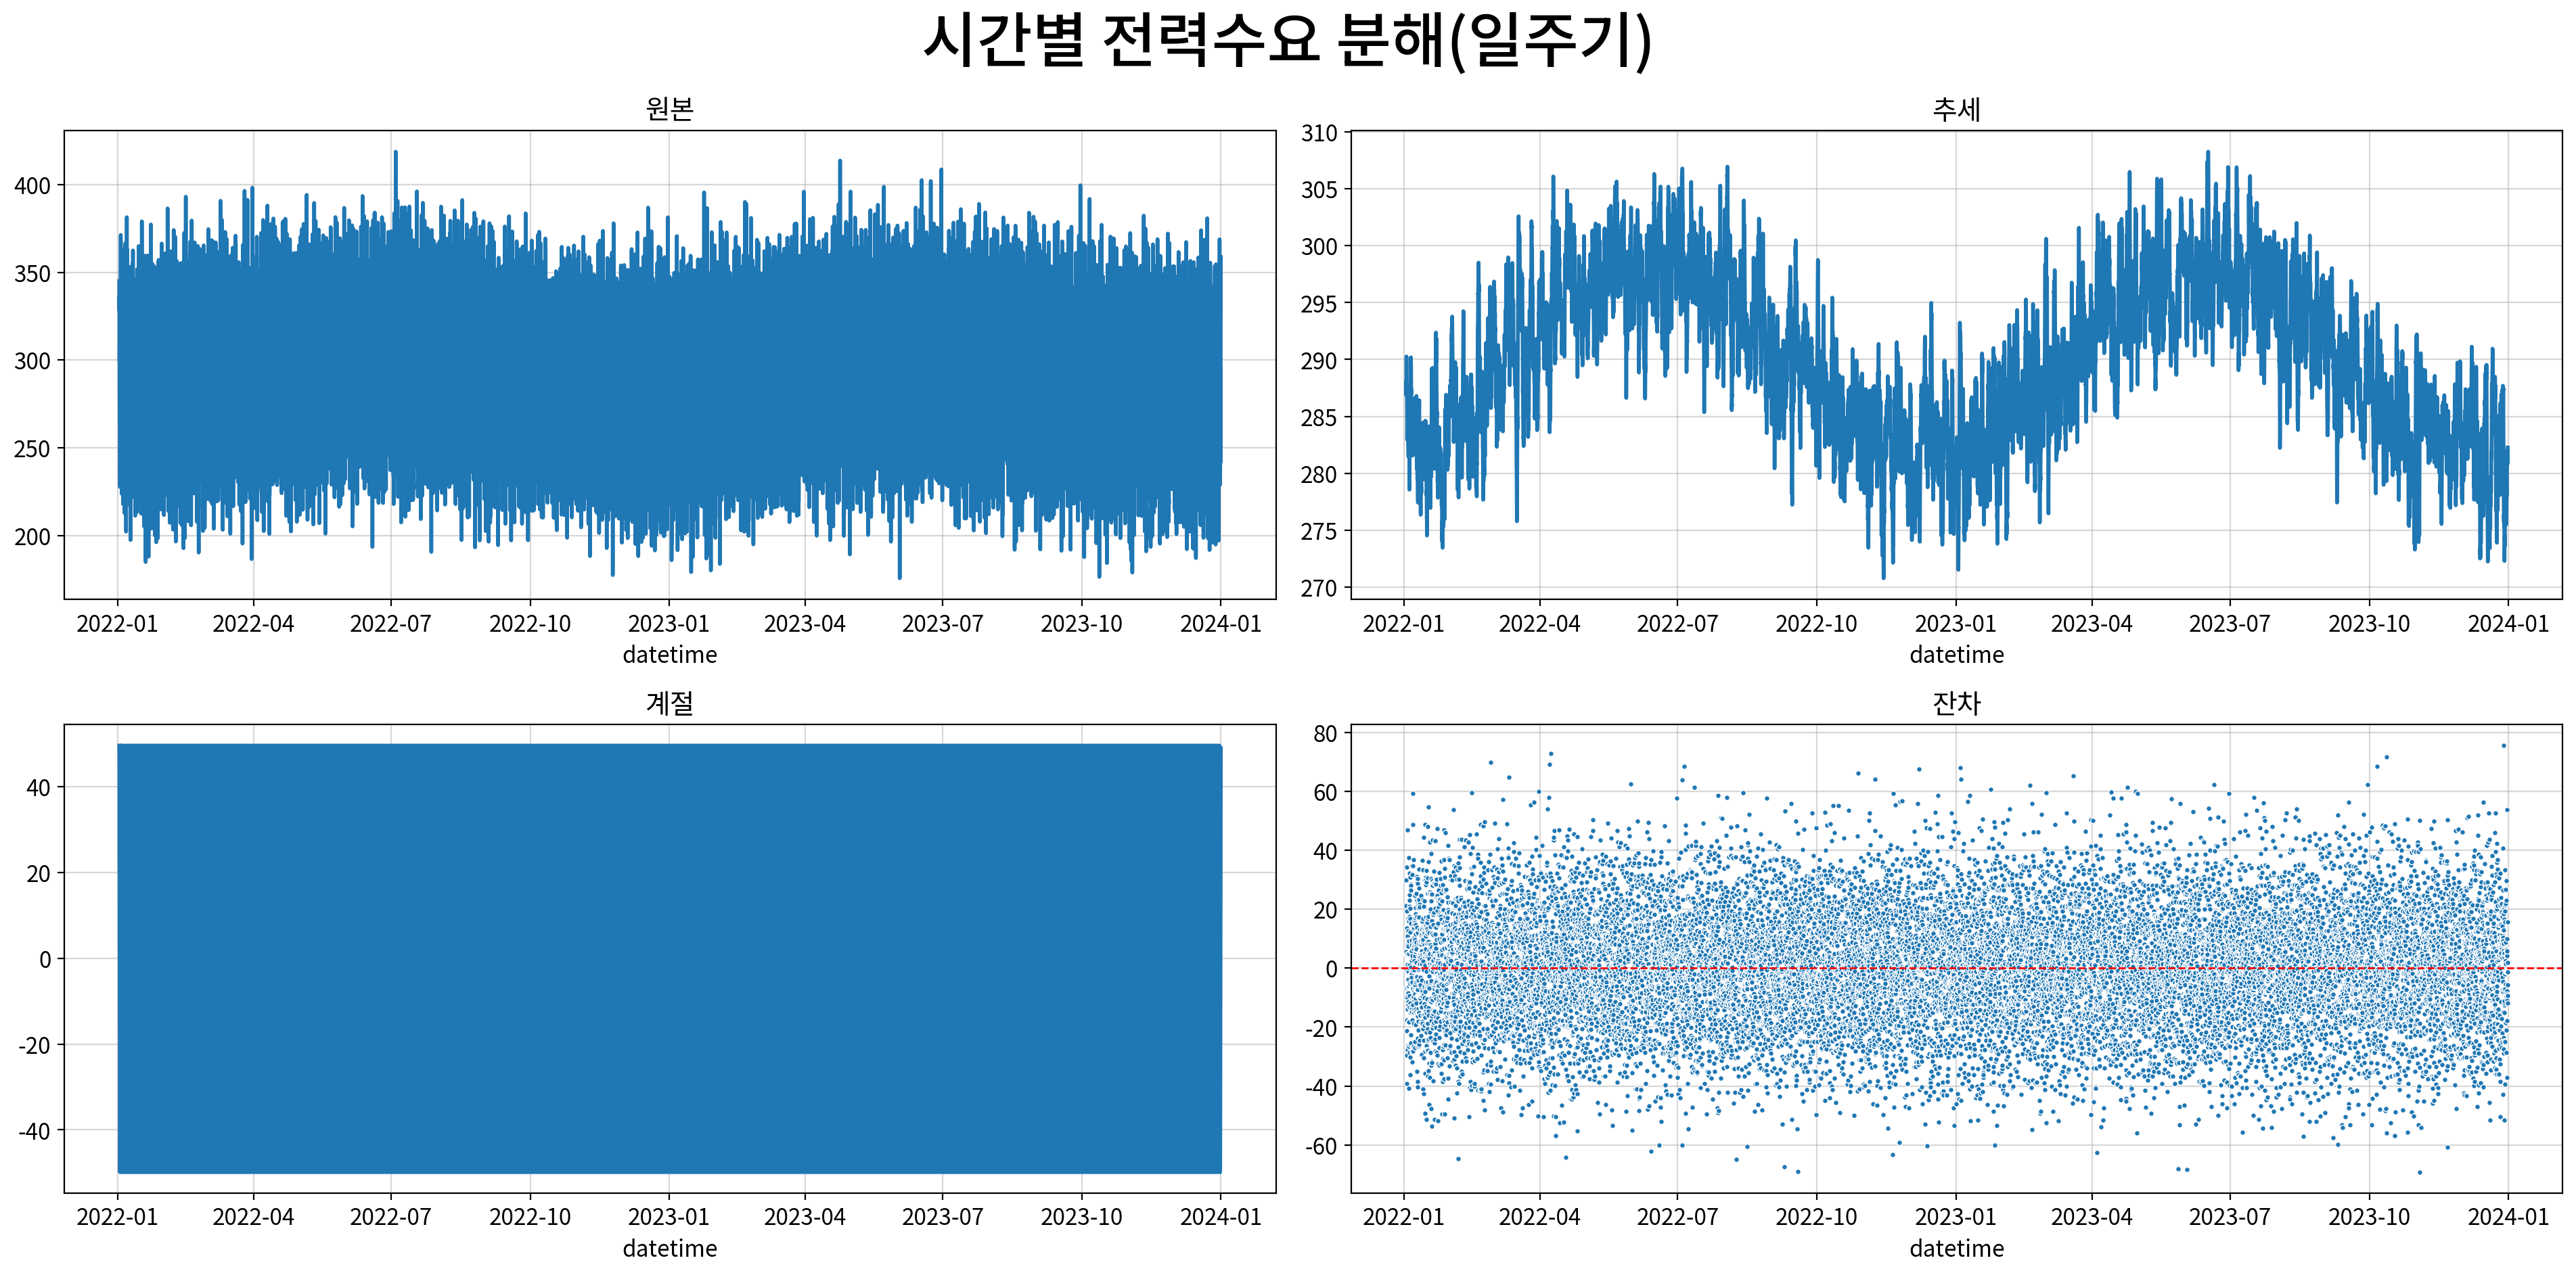

,원본,추세,계절,잔차
datetime,,,,
2022-01-02 00:00:00,345.002816,NaN,49.539424,NaN
2022-01-02 01:00:00,328.187143,NaN,46.916358,NaN
2022-01-02 02:00:00,336.269392,NaN,43.490010,NaN
2022-01-02 03:00:00,305.035233,NaN,34.236756,NaN
2022-01-02 04:00:00,299.085592,NaN,24.725611,NaN


In [27]:
decomposition_24h = my_ts.decompose(
    df1,
    period=24,
    column="load_demand_MW",
    model="additive",
    title="시간별 전력수요 분해(일주기)"
)

display(decomposition_24h.head())

#### 4-3) 주기 내 위치별 계절지수

결합 방식 : additive
최고 위치 : 1 (49.5394)
최저 위치 : 13 (-49.8441)


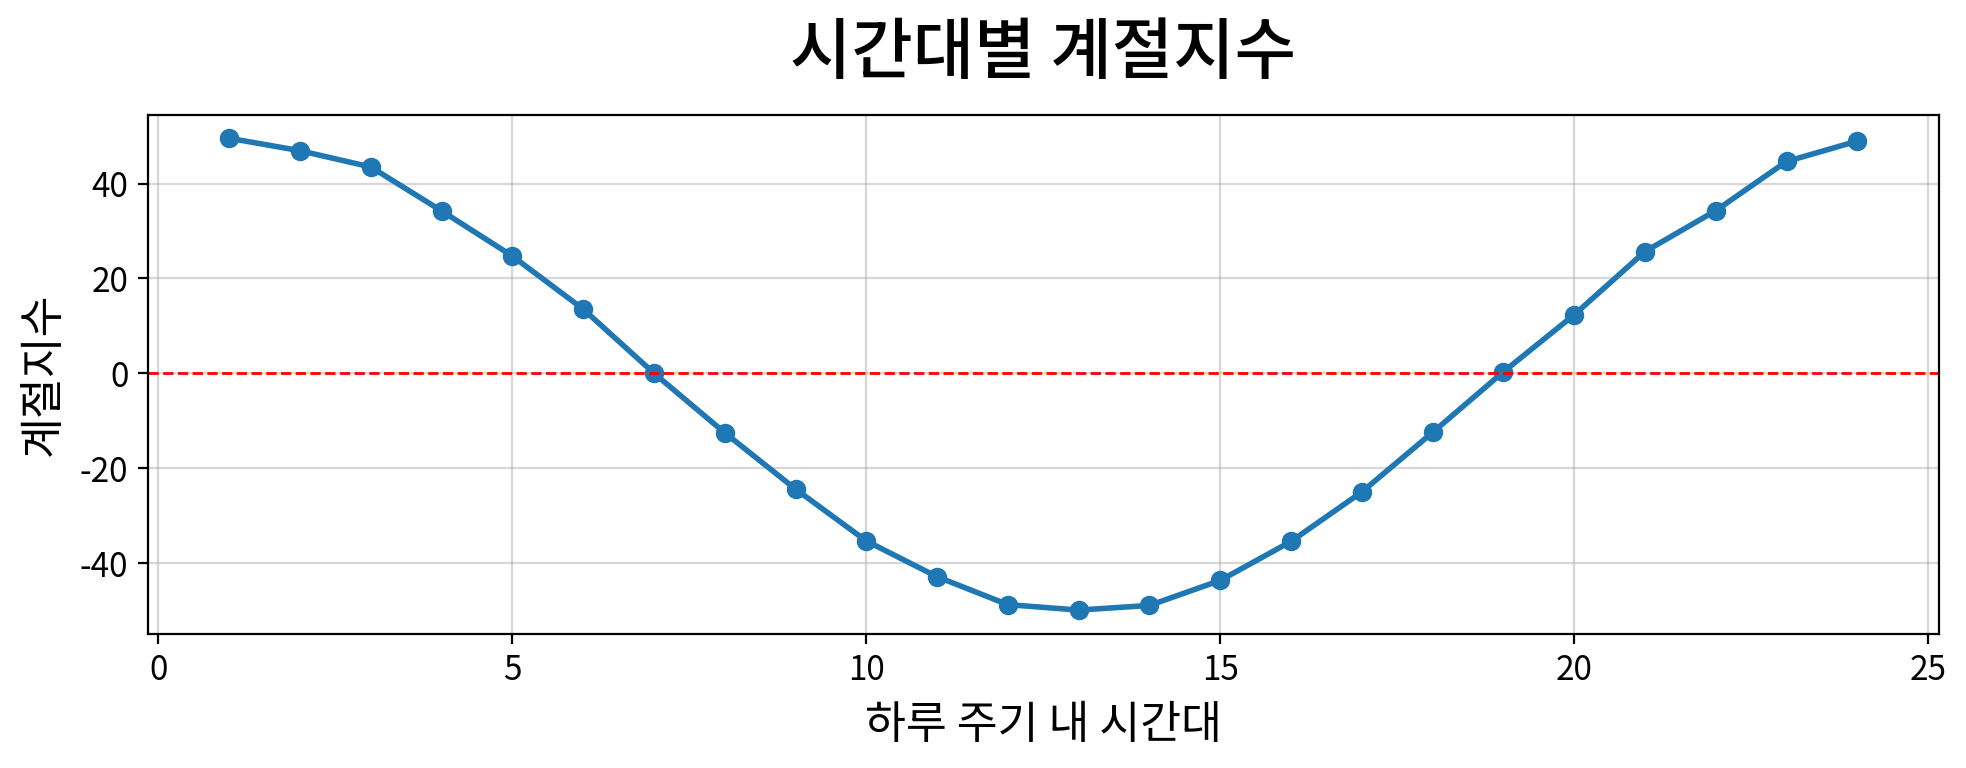

,계절지수,평균,기준 대비
주기 내 위치,,,
1,49.5394,0.0,49.539
2,46.9164,0.0,46.916
3,43.4900,0.0,43.490
4,34.2368,0.0,34.237
5,24.7256,0.0,24.726
6,13.5543,0.0,13.554
7,0.0553,0.0,0.055
8,-12.4930,0.0,-12.493
9,-24.3560,0.0,-24.356


In [33]:
seasonal_index_24h = my_ts.report_seasonal(
    df1,
    period=24,
    column="load_demand_MW",
    model="additive",
    title="시간대별 계절지수",
    xlabel="하루 주기 내 시간대",
    ylabel="계절지수"
)

display(seasonal_index_24h)

#### 4-4) 일주기·주간주기 계절성 비교

,요일,시간대,평균 전력수요
0,0,0,335.95
1,0,1,337.78
2,0,2,331.74
3,0,3,322.62
4,0,4,311.80
5,0,5,304.66
6,0,6,287.58
7,0,7,276.08
8,0,8,263.68
9,0,9,253.65


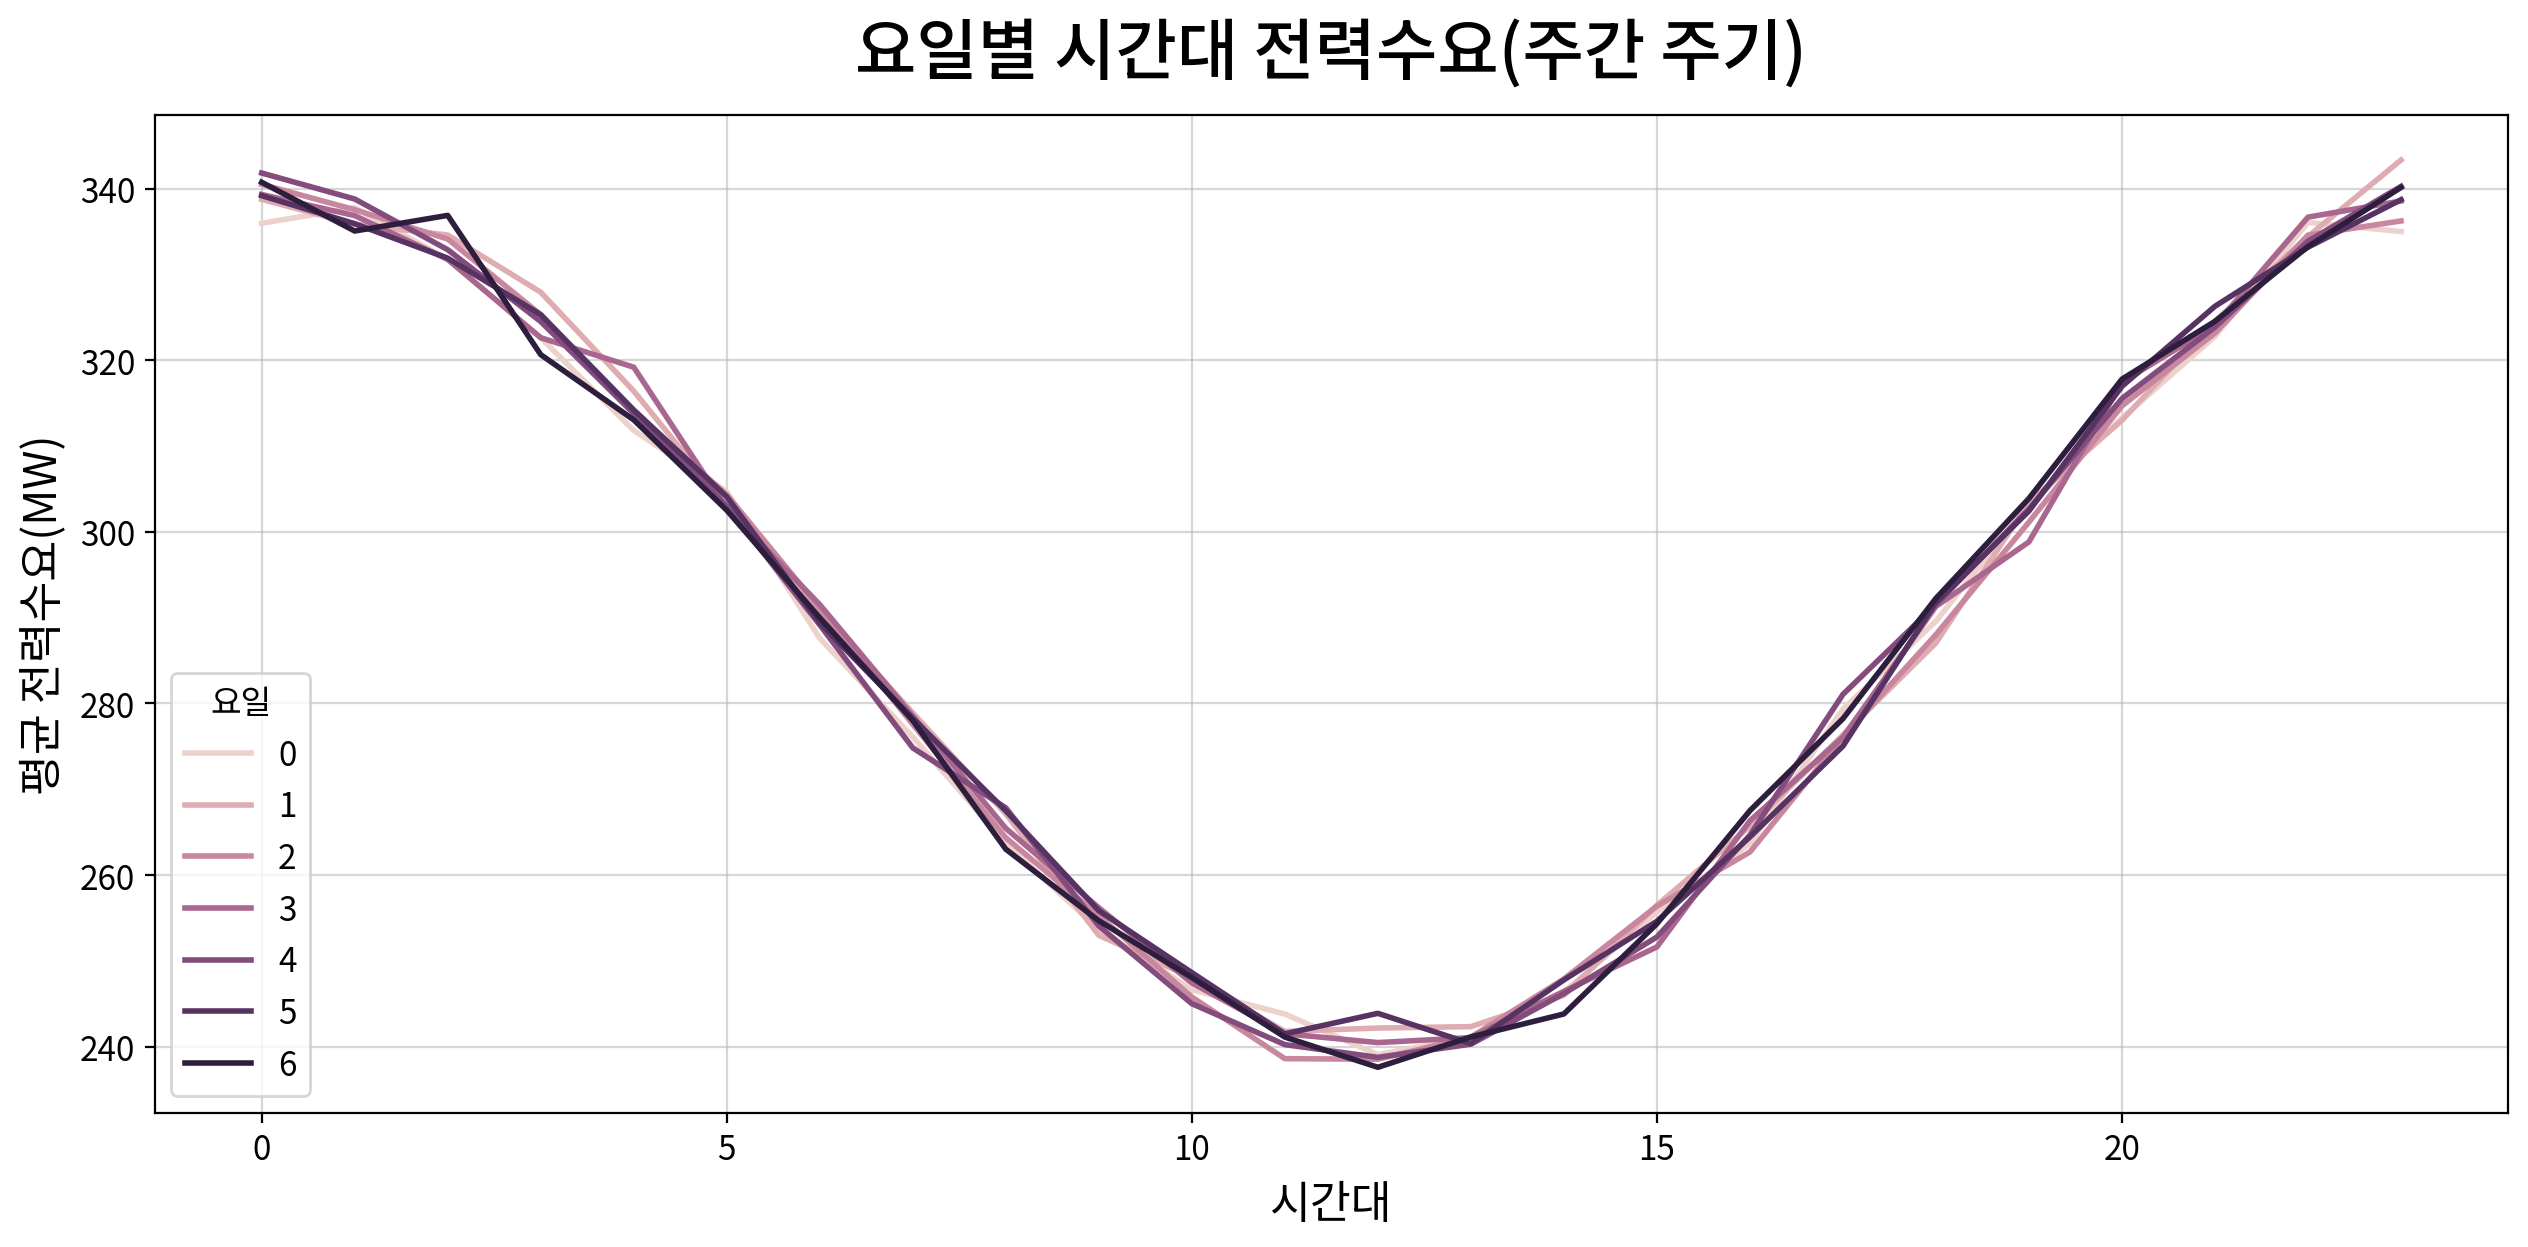

결합 방식 : additive
최고 위치 : 72 (53.1467)
최저 위치 : 13 (-52.2351)


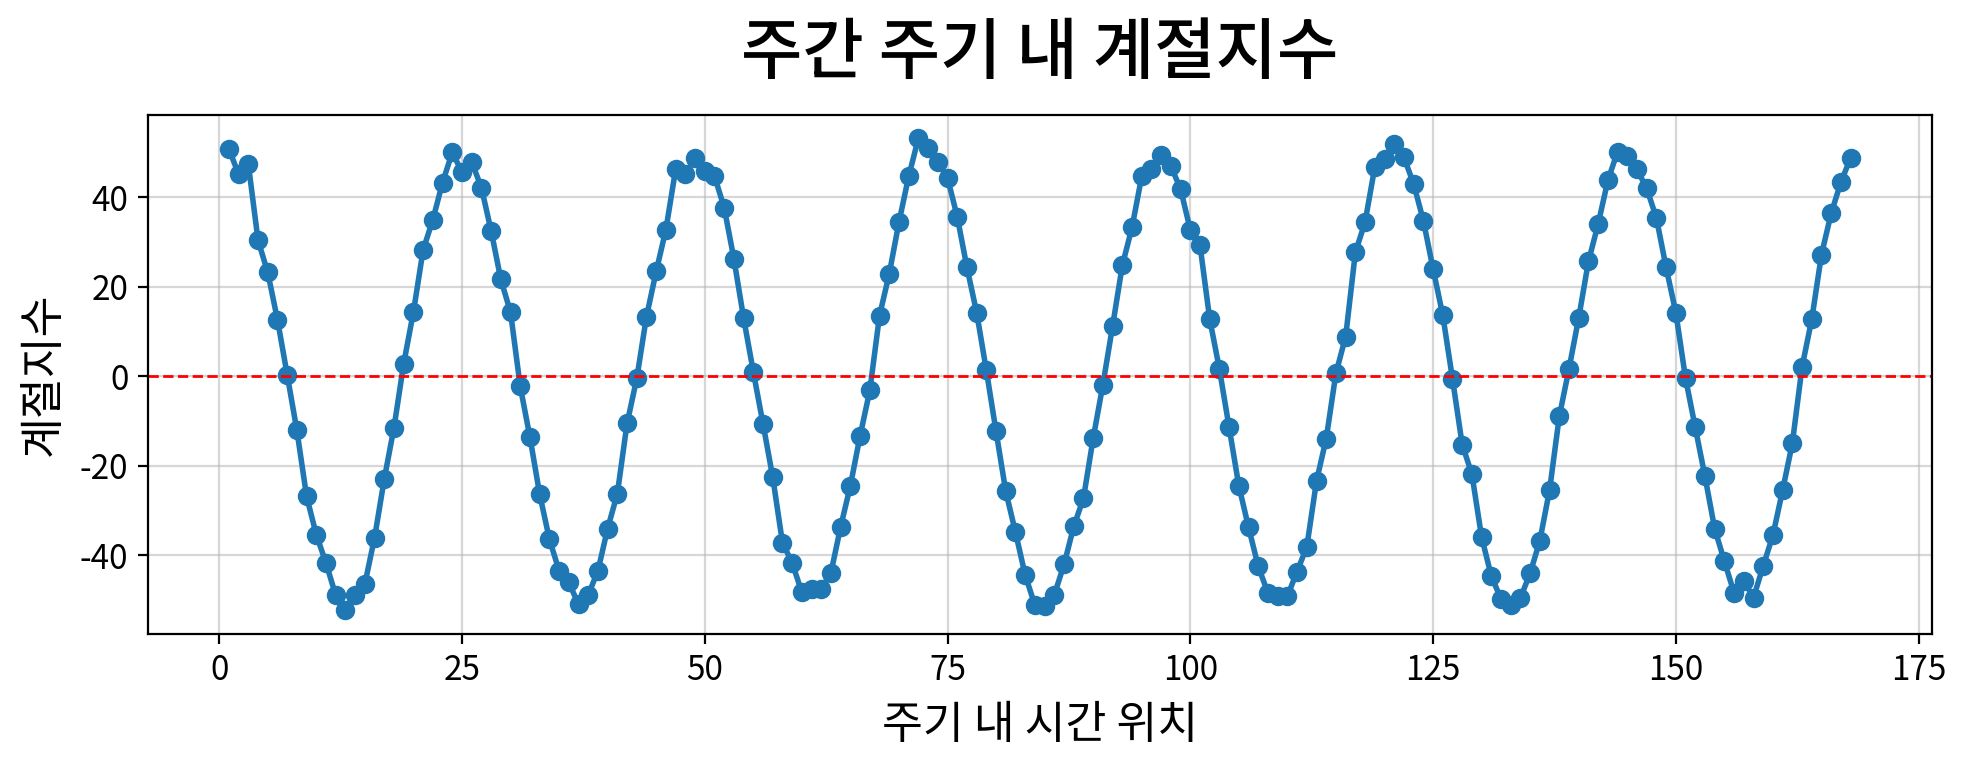

,계절지수,평균,기준 대비
주기 내 위치,,,
1,50.7590,0.0,50.759
2,45.0897,0.0,45.090
3,47.3554,0.0,47.355
4,30.3223,0.0,30.322
5,23.1817,0.0,23.182
6,12.6095,0.0,12.609
7,0.3337,0.0,0.334
8,-12.1189,0.0,-12.119
9,-26.8598,0.0,-26.860


In [29]:
weekly_source = df1[["load_demand_MW"]].copy()
weekly_source["요일"] = weekly_source.index.dayofweek
weekly_source["시간대"] = weekly_source.index.hour

weekly_pattern = (
    weekly_source.groupby(["요일", "시간대"])["load_demand_MW"]
    .mean()
    .rename("평균 전력수요")
    .reset_index()
)

display(weekly_pattern.head(10).round(2))

my_plot.lineplot(
    data=weekly_pattern,
    x="시간대", y="평균 전력수요", hue="요일",
    title="요일별 시간대 전력수요(주간 주기)",
    xlabel="시간대", ylabel="평균 전력수요(MW)"
)

seasonal_index_168h = my_ts.report_seasonal(
    df1,
    period=168,
    column="load_demand_MW",
    model="additive",
    title="주간 주기 내 계절지수",
    xlabel="주기 내 시간 위치",
    ylabel="계절지수"
)

display(seasonal_index_168h.head(24))

#### 4-5) 자기상관으로 반복 주기 확인

관측치 17496개 | 유의성 기준값 0.015 | 최대 시차 72 (상한 N/4=4374)
AR 차수 후보 (p): 2      ← PACF가 lag 2 이후 절단
MA 차수 후보 (q): 72      ← ACF가 lag 72 이후 절단
계절 AR 차수 후보 (P): 3          ←계절 PACF가 lag 72 이후 절단(판정 시차 [24, 48, 72])
계절 MA 차수 후보 (Q): 3          ←계절 ACF가 lag 72 이후 절단(판정 시차 [24, 48, 72])
→ SARIMA(2, d, 72)(3, D, 3)[24] - d·D 는 차분 단계의 결과를 넣는다


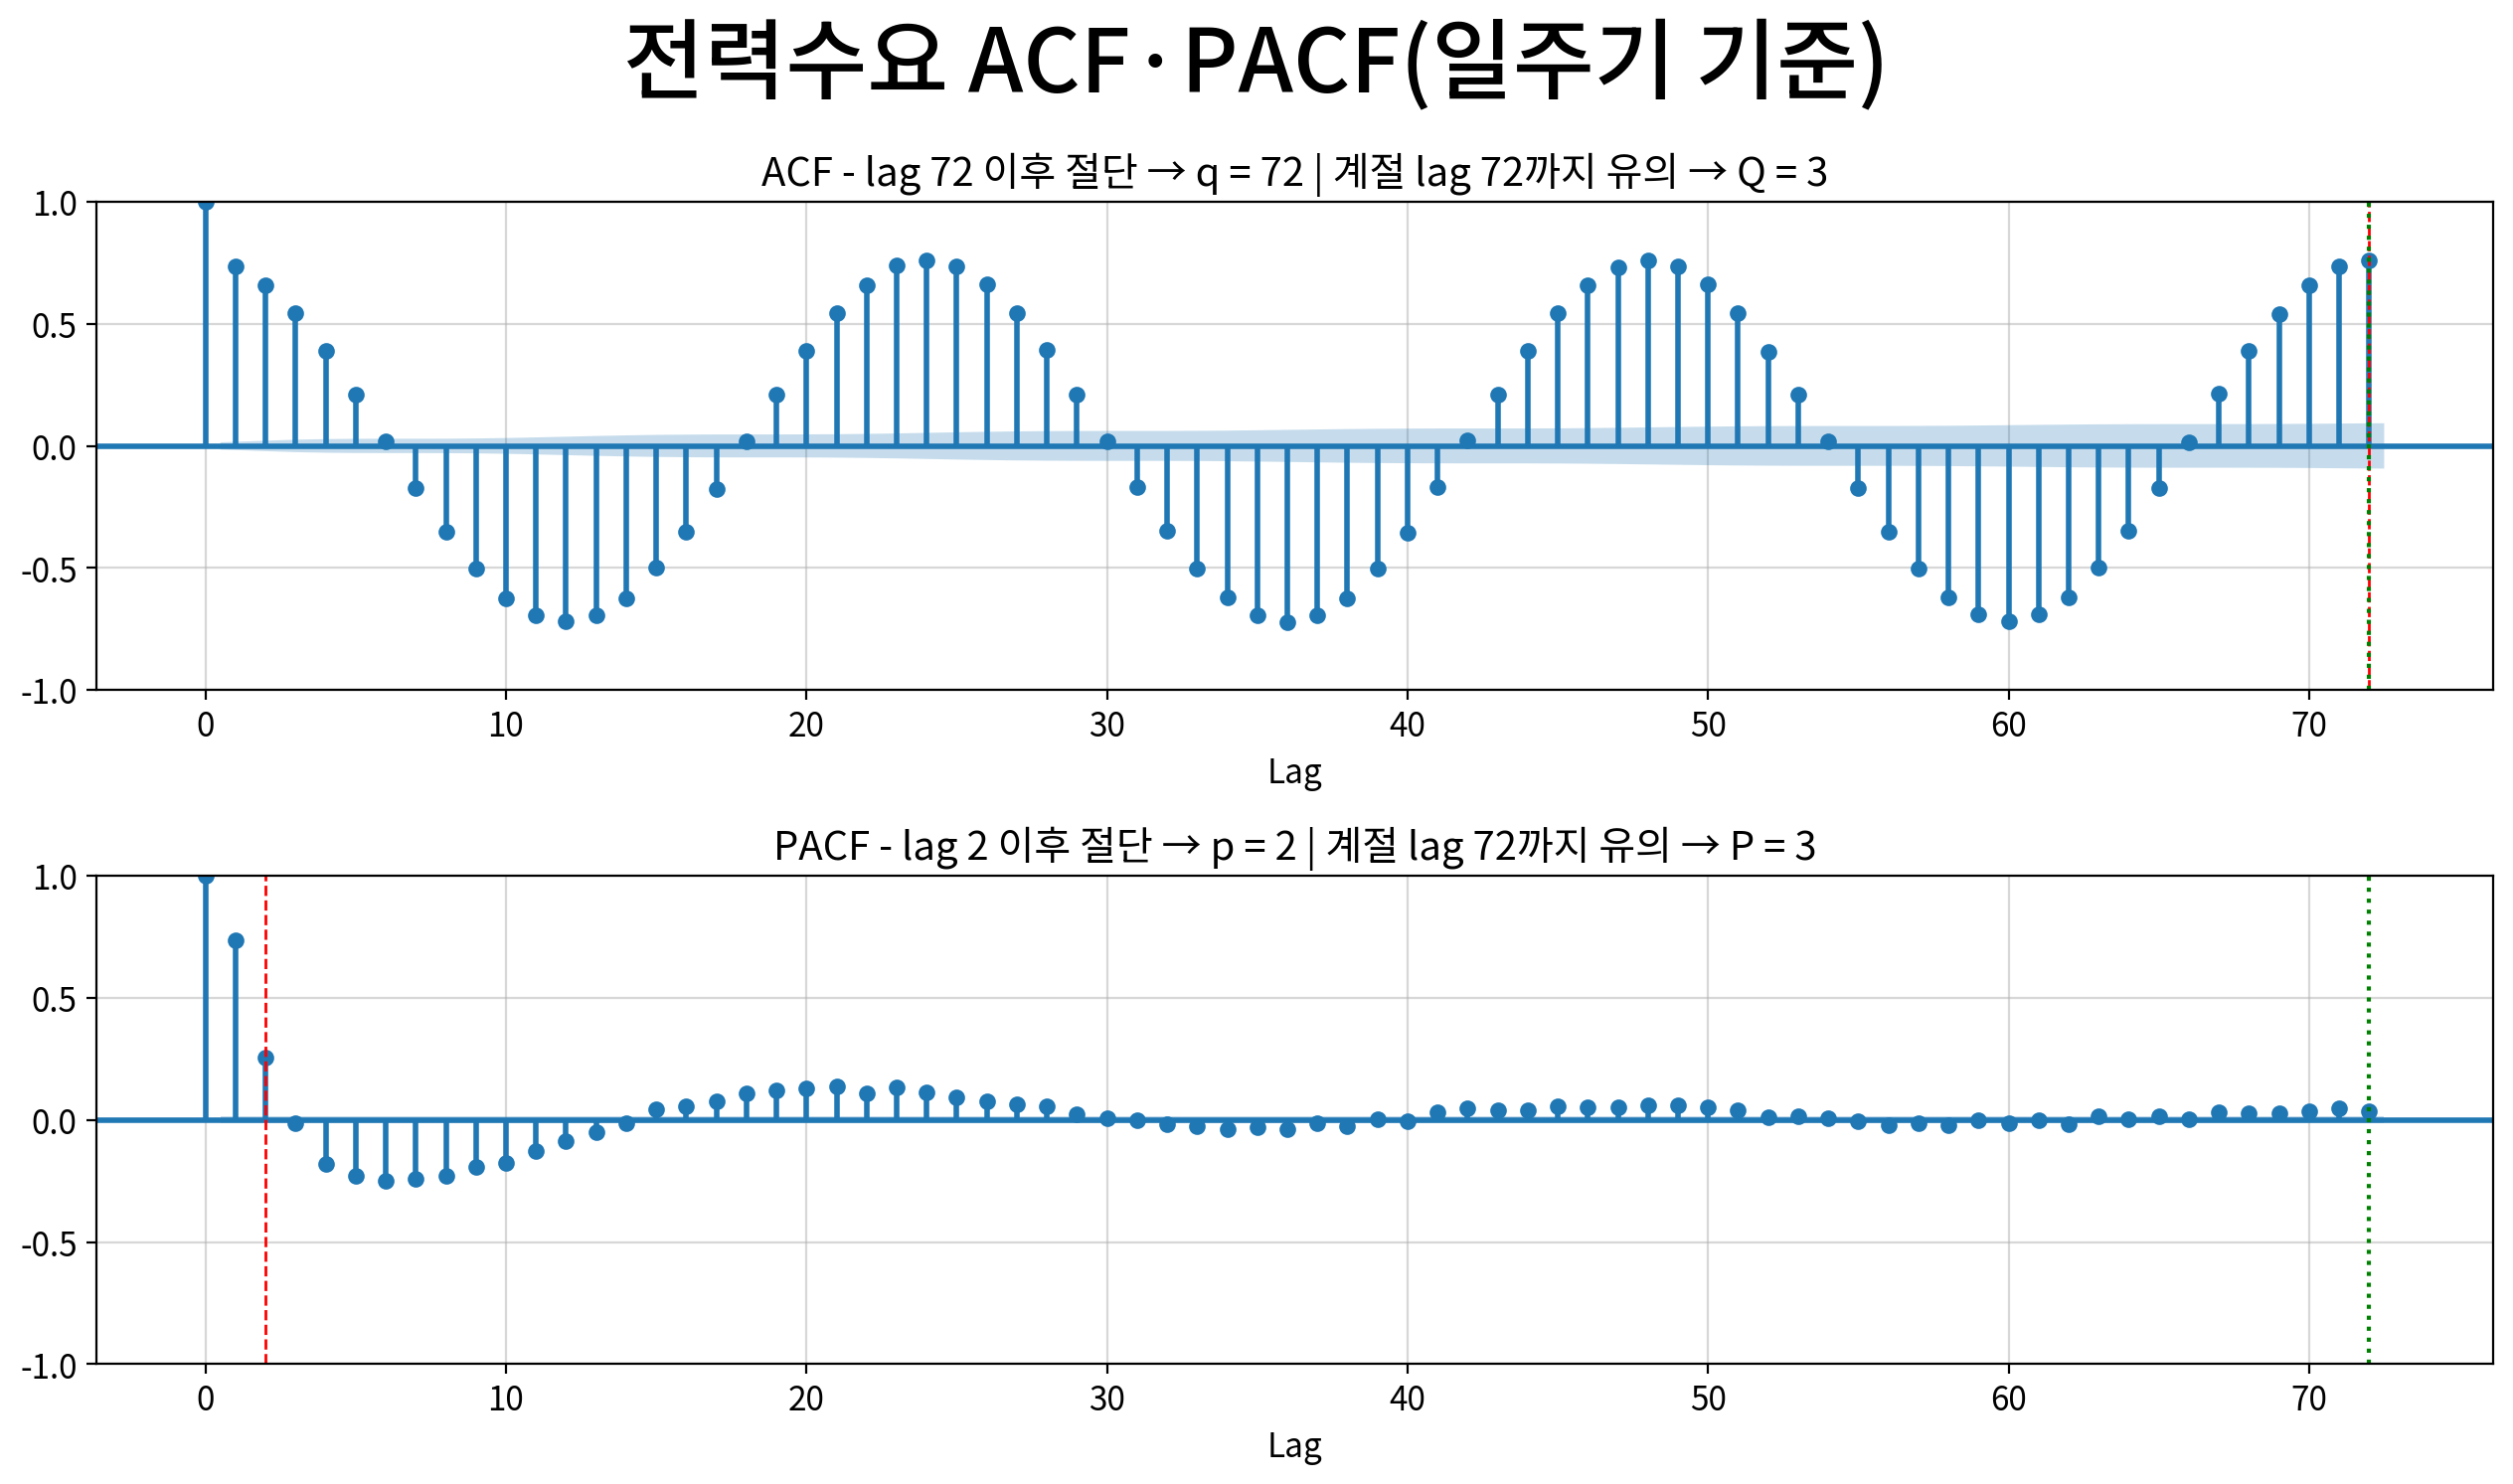

,acf,acf 유의성,pacf,pacf 유의성,기준값,p,q,P,Q
lag,,,,,,,,,
1,0.737,True,0.737,True,0.015,,,,
2,0.660,True,0.255,True,0.015,◀,,,
3,0.545,True,-0.013,False,0.015,,,,
6,0.020,True,-0.249,True,0.015,,,,
12,-0.720,True,-0.088,True,0.015,,,,
24,0.761,True,0.114,True,0.015,,,,
48,0.760,True,0.063,True,0.015,,,,
72,0.758,True,0.038,True,0.015,,◀,◀,◀


In [30]:
# 24시간 주기와 168시간 주기에서 자기상관이 반복되는지 확인합니다.
acf_24h = my_ts.auto_correlation(
    df1,
    column="load_demand_MW",
    period=24,
    title="전력수요 ACF·PACF(일주기 기준)"
)

display(acf_24h.loc[[lag for lag in [1, 2, 3, 6, 12, 24, 48, 72] if lag in acf_24h.index]])

## EDA 결과 해석

### 1. 전체 추세

- 분석 대상은 1시간 간격으로 정렬된 전력수요 시계열이며, 총 **17,496시간**의 관측치로 구성된다.
- 전체 시계열 그래프에서는 시간대별 단기 변동이 크게 나타나므로, 원본 그래프만으로 장기 추세를 판단하기는 어렵다.
- 24시간 이동평균과 시계열 분해의 추세 성분을 함께 확인한 결과, 전력수요 수준은 기간에 따라 상승·하락을 반복한다. 따라서 일정한 직선형 추세보다는 시기별 변동을 고려할 필요가 있다.

### 2. 시간대별 패턴

- 시간대별 평균 전력수요는 **0시 약 339.46MW**에서 높게 시작한 뒤 점차 감소하여 **12시 약 240.06MW**에서 가장 낮아진다.
- 이후 오후부터 다시 상승하여 23시에는 약 **338.89MW**까지 회복된다.
- 즉, 하루 안에서 전력수요가 일정하지 않고 **심야·야간에 높고 낮 시간대에 낮아지는 뚜렷한 일중 반복 패턴**이 확인된다.
- 이 결과는 전력수요에 24시간 주기가 존재할 가능성을 보여주므로, 이후 정상성 검정과 모델링에서 `period=24`를 우선 검토한다.

### 3. 요일별·주간 패턴

- 요일별 평균 전력수요는 약 **289~291MW** 범위로, 요일 자체의 평균 차이는 크지 않다.
- 그러나 요일별 시간대 그래프는 모든 요일에서 비슷한 일중 곡선을 보이며, 시간대 변화가 요일별 평균 차이보다 더 큰 영향을 주는 것으로 보인다.
- 주간 주기의 계절지수에서도 168시간을 한 주기로 하는 반복 구조가 확인된다. 주기 내 계절지수는 특정 시간 위치에서 높고 낮아지는 파형을 반복한다.
- 따라서 `요일`의 단순 평균만으로는 차이가 작아 보이지만, **요일과 시간대의 결합 패턴**은 별도로 해석해야 한다.

### 4. 계절별 패턴

- 계절별·시간대별 그래프에서 계절이 달라져도 하루 동안의 상승·하락 곡선은 대체로 유지된다.
- 이는 전력수요의 기본 구조가 계절보다 시간대에 의해 반복되는 한편, 계절에 따라 전체 수요 수준이나 변동 폭이 달라질 수 있음을 의미한다.
- 계절별 평균 차이는 기온, 습도, HDD, CDD와 함께 확인해야 하며, 현재 단계에서는 계절이 전력수요를 변화시키는 원인이라고 단정하지 않는다.

### 5. 자기상관과 반복 주기

- ACF에서 `lag=1`의 자기상관은 약 **0.737**로 높아, 바로 이전 시간의 전력수요가 현재 수요와 강하게 연결되어 있다.
- `lag=24`, `48`, `72`에서도 ACF가 각각 약 **0.761`, `0.760`, `0.758`**로 높게 나타난다.
- 이는 전력수요가 전날 같은 시간 및 여러 날 전의 같은 시간과 유사한 패턴을 보이는 **24시간 반복성**을 의미한다.
- PACF는 초기 시차에서 크게 나타난 후 빠르게 감소하므로, 단기 자기회귀 구조도 존재할 가능성이 있다.
- 단, ACF·PACF만으로 최종 ARIMA 차수를 확정하지 않고 정상성 검정과 잔차 진단 결과를 함께 확인해야 한다.

### 6. EDA 종합 결론

- 이 데이터에는 **강한 일중 계절성(`24시간`)**과 **주간 반복성(`168시간`)**이 존재한다.
- 전력수요는 시간에 따라 독립적으로 변하지 않으며, 직전 시점과 전날 같은 시점의 수요에 영향을 받는 시계열 구조를 가진다.
- 요일별 단순 평균 차이는 작지만, 요일과 시간대를 결합하면 주간 패턴을 확인할 수 있다.
- 따라서 다음 단계에서는 원본 시계열을 그대로 모델링하기보다 다음 검정을 먼저 수행한다.
  - ADF·KPSS 정상성 검정
  - `24시간` 계절차분 필요성 검토
  - Ljung-Box 자기상관 검정
  - 검정 결과에 따른 로그변환·일반차분·계절차분 결정

> **주의:** 위 결과는 전력수요의 시간적 연관성과 반복 패턴을 설명하는 탐색적 결과이며, 기온이나 습도가 전력수요를 인과적으로 변화시킨다는 의미는 아니다.

## #5. 추론통계 및 시계열 검정

시계열의 정상성, 자기상관, 계절별 차이를 검정하고 이후 전처리 방향을 결정한다.

In [39]:
from statsmodels.tsa.stattools import kpss

series = df1["load_demand_MW"].dropna()

adf_result = my_ts.adf_test(series, name="원본 전력수요")

kpss_stat, kpss_pvalue, kpss_lags, kpss_critical = kpss(
    series,
    regression="c",
    nlags="auto"
)

kpss_result = pd.DataFrame([{
    "검정통계량(KPSS)": round(kpss_stat, 4),
    "p-value": round(kpss_pvalue, 4),
    "사용 시차": kpss_lags,
    "1% 기각값": kpss_critical["1%"],
    "5% 기각값": kpss_critical["5%"],
    "10% 기각값": kpss_critical["10%"],
    "판정": "정상" if kpss_pvalue >= 0.05 else "비정상"
}], index=["원본 전력수요"])

display(adf_result)
display(kpss_result)

def stationarity_result(data, name):
    adf_pvalue = my_ts.adf_test(data, name=name)["p-value"].iloc[0]
    kpss_stat, kpss_pvalue, _, _ = kpss(data.dropna(), regression="c", nlags="auto")
    return {
        "대상": name,
        "ADF p-value": adf_pvalue,
        "KPSS p-value": round(kpss_pvalue, 4),
        "ADF 판정": "정상" if adf_pvalue < 0.05 else "비정상",
        "KPSS 판정": "정상" if kpss_pvalue >= 0.05 else "비정상"
    }

stationarity_table = pd.DataFrame([
    stationarity_result(series, "원본"),
    stationarity_result(series.diff().dropna(), "1차 차분"),
    stationarity_result(series.diff(24).dropna(), "24시간 계절차분"),
    stationarity_result(series.diff().diff(24).dropna(), "1차 + 24시간 계절차분")
]).set_index("대상")

display(stationarity_table)

C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3555537828.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_pvalue, kpss_lags, kpss_critical = kpss(


,관측치 수,검정통계량(ADF),p-value,사용 시차,1% 기각값,5% 기각값,10% 기각값,표준편차,정상성,판정
원본 전력수요,17496,-9.718,0.0,44,-3.431,-2.862,-2.567,40.989,True,정상


,검정통계량(KPSS),p-value,사용 시차,1% 기각값,5% 기각값,10% 기각값,판정
원본 전력수요,2.0461,0.01,28,0.739,0.463,0.347,비정상


C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3555537828.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(data.dropna(), regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3555537828.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(data.dropna(), regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3555537828.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(data.dropna(), regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\35555378

,ADF p-value,KPSS p-value,ADF 판정,KPSS 판정
대상,,,,
원본,0.0,0.01,정상,비정상
1차 차분,0.0,0.10,정상,정상
24시간 계절차분,0.0,0.10,정상,정상
1차 + 24시간 계절차분,0.0,0.10,정상,정상


#### 5-2. 자기상관 검정: Ljung-Box

Ljung-Box 검정의 귀무가설은 지정한 시차까지 자기상관이 없다는 것이다. p-value가 0.05보다 작으면 자기상관이 남아 있다고 판단한다.

In [35]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljungbox_original = acorr_ljungbox(
    series,
    lags=[1, 24, 48, 168],
    return_df=True
).rename(columns={"lb_stat": "검정통계량", "lb_pvalue": "p-value"})

seasonal_diff_24 = series.diff(24).dropna()
ljungbox_diff = acorr_ljungbox(
    seasonal_diff_24,
    lags=[1, 24, 48, 168],
    return_df=True
).rename(columns={"lb_stat": "검정통계량", "lb_pvalue": "p-value"})

ljungbox_original["판정"] = np.where(
    ljungbox_original["p-value"] < 0.05,
    "자기상관 있음",
    "자기상관 없음"
)
ljungbox_diff["판정"] = np.where(
    ljungbox_diff["p-value"] < 0.05,
    "자기상관 있음",
    "자기상관 없음"
)

print("원본 전력수요")
display(ljungbox_original.round(4))
print("24시간 계절차분 후")
display(ljungbox_diff.round(4))

원본 전력수요


,검정통계량,p-value,판정
1,9500.9567,0.0,자기상관 있음
24,115397.0667,0.0,자기상관 있음
48,230575.6991,0.0,자기상관 있음
168,804275.3259,0.0,자기상관 있음


24시간 계절차분 후


,검정통계량,p-value,판정
1,0.1421,0.7062,자기상관 없음
24,4401.0232,0.0000,자기상관 있음
48,4449.2073,0.0000,자기상관 있음
168,4622.8681,0.0000,자기상관 있음


#### 5-3. 계절·요일별 집단 차이 검정

계절과 요일을 집단으로 나누어 전력수요 분포의 차이를 검정한다. 정규성·등분산성을 강하게 가정하지 않기 위해 Kruskal-Wallis 비모수 검정을 사용한다.

- 귀무가설: 모든 집단의 전력수요 분포가 같다.
- 대립가설: 하나 이상의 집단이 다르다.

In [36]:
from scipy.stats import kruskal

season_groups = [
    group["load_demand_MW"].dropna().values
    for _, group in df1.groupby("season", observed=True)
]
weekday_groups = [
    group["load_demand_MW"].dropna().values
    for _, group in df1.groupby("day_of_week", observed=True)
]

season_h, season_p = kruskal(*season_groups)
weekday_h, weekday_p = kruskal(*weekday_groups)

group_test_result = pd.DataFrame([
    {
        "집단 기준": "계절",
        "검정": "Kruskal-Wallis",
        "검정통계량": round(season_h, 4),
        "p-value": round(season_p, 4),
        "판정": "집단 간 차이 있음" if season_p < 0.05 else "집단 간 차이 없음"
    },
    {
        "집단 기준": "요일",
        "검정": "Kruskal-Wallis",
        "검정통계량": round(weekday_h, 4),
        "p-value": round(weekday_p, 4),
        "판정": "집단 간 차이 있음" if weekday_p < 0.05 else "집단 간 차이 없음"
    }
]).set_index("집단 기준")

display(group_test_result)

,검정,검정통계량,p-value,판정
집단 기준,,,,
계절,Kruskal-Wallis,255.6153,0.0000,집단 간 차이 있음
요일,Kruskal-Wallis,1.6898,0.9459,집단 간 차이 없음


#### 5-4. 선택 검정: Granger 인과성

Granger 검정은 인과관계를 증명하는 검정이 아니라, 한 변수의 과거값이 다른 변수의 미래값을 설명하는 데 추가적인 정보를 제공하는지 확인하는 검정이다. 여기서는 정상성을 고려해 1차 차분한 전력수요와 기온을 사용한다.

In [37]:
from statsmodels.tsa.stattools import grangercausalitytests

# 두 변수 모두 차분한 뒤 결측치를 제거한다.
granger_data = pd.concat([
    series.diff().rename("전력수요"),
    df1["temperature_C"].diff().rename("기온")
], axis=1).dropna()

def granger_summary(data, effect, cause, maxlag=24):
    test_data = data[[effect, cause]]
    test_result = grangercausalitytests(test_data, maxlag=maxlag, verbose=False)
    result = []

    for lag, output in test_result.items():
        pvalue = output[0]["ssr_ftest"][1]
        result.append({
            "시차": lag,
            "F-test p-value": pvalue,
            "판정": "예측 정보 있음" if pvalue < 0.05 else "예측 정보 없음"
        })

    return pd.DataFrame(result).set_index("시차")

temperature_to_load = granger_summary(
    granger_data, effect="전력수요", cause="기온", maxlag=24
)
load_to_temperature = granger_summary(
    granger_data, effect="기온", cause="전력수요", maxlag=24
)

print("기온의 과거값 → 전력수요")
display(temperature_to_load.round(4))
print("전력수요의 과거값 → 기온")
display(load_to_temperature.round(4))

c:\Users\LG\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
c:\Users\LG\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


기온의 과거값 → 전력수요


,F-test p-value,판정
시차,,
1,0.9612,예측 정보 없음
2,0.0232,예측 정보 있음
3,0.0834,예측 정보 없음
4,0.0411,예측 정보 있음
5,0.0725,예측 정보 없음
6,0.1019,예측 정보 없음
7,0.1229,예측 정보 없음
8,0.1442,예측 정보 없음
9,0.2089,예측 정보 없음


전력수요의 과거값 → 기온


,F-test p-value,판정
시차,,
1,0.4411,예측 정보 없음
2,0.8436,예측 정보 없음
3,0.7796,예측 정보 없음
4,0.8398,예측 정보 없음
5,0.8369,예측 정보 없음
6,0.4886,예측 정보 없음
7,0.5359,예측 정보 없음
8,0.5502,예측 정보 없음
9,0.6486,예측 정보 없음


#### 5-5. 검정 결과에 따른 전처리 방향 결정

검정 결과를 바탕으로 과도한 변환을 피하면서 모델링 후보를 비교한다. 로그변환은 분산이 수준에 비례해 커질 때 적용하고, 차분과 계절차분은 정상성과 반복 구조를 기준으로 판단한다.

In [38]:
candidate_series = {
    "원본": series,
    "로그변환": np.log(series),
    "1차 차분": my_ts.transform(series, diff=1),
    "24시간 계절차분": my_ts.transform(series, seasonal_diff=1, period=24),
    "1차 + 24시간 계절차분": my_ts.transform(series, diff=1, seasonal_diff=1, period=24),
    "로그 + 24시간 계절차분": my_ts.transform(series, log=True, seasonal_diff=1, period=24)
}

candidate_result = []
for name, candidate in candidate_series.items():
    candidate = candidate.dropna()
    adf_pvalue = my_ts.adf_test(candidate, name=name)["p-value"].iloc[0]
    kpss_stat, kpss_pvalue, _, _ = kpss(candidate, regression="c", nlags="auto")
    candidate_result.append({
        "변환": name,
        "ADF p-value": adf_pvalue,
        "KPSS p-value": round(kpss_pvalue, 4),
        "ADF 판정": "정상" if adf_pvalue < 0.05 else "비정상",
        "KPSS 판정": "정상" if kpss_pvalue >= 0.05 else "비정상",
        "표준편차": round(candidate.std(), 3)
    })

transformation_result = pd.DataFrame(candidate_result).set_index("변환")
display(transformation_result)

C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3586622507.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(candidate, regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3586622507.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(candidate, regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3586622507.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_pvalue, _, _ = kpss(candidate, regression="c", nlags="auto")
C:\Users\LG\AppData\Local\Temp\ipykernel_19632\3586622507.py:14: In

,ADF p-value,KPSS p-value,ADF 판정,KPSS 판정,표준편차
변환,,,,,
원본,0.0,0.01,정상,비정상,40.989
로그변환,0.0,0.01,정상,비정상,0.144
1차 차분,0.0,0.10,정상,정상,29.730
24시간 계절차분,0.0,0.10,정상,정상,28.286
1차 + 24시간 계절차분,0.0,0.10,정상,정상,39.945
로그 + 24시간 계절차분,0.0,0.10,정상,정상,0.100


#### 5-6. 추론통계 및 시계열 검정 결과 해석

### 1. 정상성 검정 결과

- 원본 전력수요는 ADF 검정에서 `p < .001`로 정상성을 지지했지만, KPSS 검정에서는 `p = .01`로 비정상 판정을 받았다.
- 두 검정의 결과가 일치하지 않으므로 원본 시계열을 정상이라고 단정하지 않고, 반복 구조와 차분 후보를 함께 검토했다.
- 로그변환만 적용한 경우에도 KPSS는 비정상으로 나타났다. 따라서 로그변환만으로는 추세 또는 계절 구조가 충분히 제거되지 않는다.
- `1차 차분`, `24시간 계절차분`, `1차 + 24시간 계절차분`은 ADF와 KPSS를 모두 만족했다.
- 후보 중 표준편차는 `24시간 계절차분`이 약 **28.286**으로 `1차 차분`의 약 **29.730**보다 작았다. 따라서 현재 단계에서는 **24시간 계절차분을 기본 전처리 후보**로 둔다.
- 다만 24시간 계절차분 후에도 `lag=24·48·168`의 자기상관이 남아 있으므로, 계절성이 완전히 제거되었다고 단정할 수는 없다.

### 2. 자기상관 검정 결과

- 원본 전력수요는 Ljung-Box 검정에서 `lag=1·24·48·168` 모두 `p < .001`로 자기상관이 유의했다.
- 이는 전력수요가 독립적인 관측값이 아니라 직전 시점과 이전 날짜의 같은 시점에 의존한다는 의미다.
- 24시간 계절차분 후 `lag=1`에서는 `p = .7062`로 자기상관이 유의하지 않게 되었다.
- 그러나 `lag=24·48·168`에서는 여전히 `p < .001`이므로, 24시간 주기와 주간 구조가 일부 남아 있다.
- 따라서 이후 모델링에서는 계절항을 포함한 모형이나 추가적인 시차변수를 검토해야 한다.

### 3. 계절·요일별 집단 차이

- 계절별 전력수요 차이는 Kruskal-Wallis 검정에서 `H = 255.6153`, `p < .001`로 유의했다.
- 실제 평균도 Summer 약 **296.12MW**, Spring 약 **294.02MW**, Autumn 약 **285.72MW**, Winter 약 **283.57MW** 순으로 차이가 있었다.
- 반면 요일별 단순 평균 차이는 `H = 1.6898`, `p = .9459`로 유의하지 않았다.
- 따라서 요일 자체의 평균 차이는 크지 않지만, EDA에서 확인한 것처럼 요일과 시간대를 결합한 주간 패턴은 별도로 고려해야 한다.

### 4. Granger 검정 결과

- 차분한 기온의 과거값이 전력수요의 미래값에 추가 정보를 제공하는지 검정한 결과, `lag=2`에서 `p = .0232`, `lag=4`에서 `p = .0411`로 유의했다.
- 그러나 나머지 시차 대부분에서는 유의하지 않았고, 전력수요의 과거값이 기온을 설명한다는 방향은 유의하지 않았다.
- 따라서 기온의 과거값과 전력수요 사이에 일부 단기 선행관계가 있을 가능성은 있지만, 이를 기온이 전력수요를 인과적으로 변화시킨다는 의미로 해석할 수는 없다.
- 기온의 효과를 확인하려면 계절성과 시간대 효과를 통제한 모형에서 추가로 검증해야 한다.

### 5. 전처리 방향 최종 정리

| 항목 | 판단 |
|---|---|
| 로그변환 | 현재 기본 적용은 보류하고, 분산 안정화가 필요한지 추가 확인 |
| 일반차분 | 정상성 확보 후보이나 24시간 계절차분보다 우선순위가 낮음 |
| 24시간 계절차분 | 일주기와 정상성을 고려한 기본 후보로 채택 |
| 168시간 계절차분 | 주간 자기상관이 남아 있어 추가 후보로 검토 |
| 1차 + 24시간 계절차분 | 정상성은 확보되지만 과도한 차분 가능성을 확인해야 함 |

> **결론:** 원본 전력수요는 강한 시간적 자기상관과 계절성을 가진다. 다음 모델링 전 단계에서는 `24시간 계절차분` 시계열을 기본 후보로 사용하고, `1차 차분`, `168시간 계절차분`, 로그변환 조합은 잔차 자기상관과 모델 성능을 비교하여 최종 결정한다.

> **주의:** KPSS의 일부 p-value는 통계량이 표의 범위를 벗어나 `0.01` 또는 `0.10`으로 표시된 경계값이다. 이는 실제 p-value가 해당 범위의 바깥이라는 뜻이므로, 경계값 자체를 정확한 p-value로 해석하지 않는다.